## **Celda 1: Importación de librerías y conexión a Google Drive**

### **1.1 Importación de librerías**

In [2]:
import os
import re
import json
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from google.colab import drive

# Preprocesamiento y construcción del modelo
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone

# Evaluación del modelo
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Configuración de reproducibilidad
RANDOM_STATE = 42

print("Librerías importadas correctamente")

Librerías importadas correctamente


### **1.2 Conexión a Google Drive**

In [3]:
drive.mount('/content/drive')

print("Google Drive conectado correctamente")

Mounted at /content/drive
Google Drive conectado correctamente


## **Celda 2: Cargar archivos CSV**

In [4]:
RUTA_DRIVE = "/content/drive/MyDrive/Kipu FraudShield/datos"

for carpeta_actual, subcarpetas, archivos in os.walk(RUTA_DRIVE):
    csv_encontrados = [
        archivo for archivo in archivos
        if archivo.lower().endswith(".csv")
    ]

    for archivo in csv_encontrados:
        print(os.path.join(carpeta_actual, archivo))

print()
# Cargar los cuatro archivos CSV
datos = {
    "transacciones": pd.read_csv(os.path.join(RUTA_DRIVE, "transacciones.csv")),
    "usuarios": pd.read_csv(os.path.join(RUTA_DRIVE, "usuarios.csv")),
    "dispositivos": pd.read_csv(os.path.join(RUTA_DRIVE, "dispositivos.csv")),
    "lista_negra": pd.read_csv(os.path.join(RUTA_DRIVE, "lista_negra.csv"))
}

# Verificar que se cargaron correctamente
for nombre, df in datos.items():
     print(f"{nombre}: {df.shape[0]} filas y {df.shape[1]} columnas")


/content/drive/MyDrive/Kipu FraudShield/datos/lista_negra.csv
/content/drive/MyDrive/Kipu FraudShield/datos/transacciones.csv
/content/drive/MyDrive/Kipu FraudShield/datos/usuarios.csv
/content/drive/MyDrive/Kipu FraudShield/datos/dispositivos.csv

transacciones: 28421 filas y 19 columnas
usuarios: 5038 filas y 10 columnas
dispositivos: 7000 filas y 7 columnas
lista_negra: 350 filas y 7 columnas


### **2.1 Exploración inicial de variables y categorías**

In [5]:
# Exploración de variables categóricas
for tabla, columnas in {
    "transacciones": [
        "es_fraude", "resultado_autorizacion", "monto",
        "moneda", "canal", "pais_transaccion"],
    "usuarios": [
        "pais", "segmento", "nivel_kyc",
        "verificado", "telefono_verificado"],
    "dispositivos": [
        "tipo", "sistema_operativo", "emulador", "pais_declarado"],
    "lista_negra": [
        "tipo", "motivo", "vigente"]
}.items():

    print("\n" + "=" * 65)
    print("Tabla:", tabla)

    for columna in columnas:
        print(f"\n{columna}")
        print("Valores distintos:", datos[tabla][columna].nunique(dropna=False))
        print(datos[tabla][columna].value_counts(dropna=False).head(12))

# Revisión de identificadores duplicados
for tabla, columna_id in {
    "transacciones": "transaccion_id",
    "usuarios": "usuario_id",
    "dispositivos": "dispositivo_id",
    "lista_negra": "entrada_id"
}.items():

    serie = datos[tabla][columna_id]

    print(f"\n{tabla}:")
    print("Filas con identificadores repetidos:", int(serie.duplicated().sum()))
    print("Cantidad de identificadores distintos repetidos:", int(serie[serie.duplicated(keep=False)].nunique()))

# Exploración de montos
print("\nMuestra de montos")
print(datos["transacciones"]["monto"].astype(str).value_counts().head(20))

# Exploración de fechas
print("\nMuestra de fechas")
print(datos["transacciones"]["timestamp"].head(10).to_list())

# Exploración de etiquetas de fraude
print("\nEtiquetas de fraude")
print(datos["transacciones"]["es_fraude"].value_counts(dropna=False))

print("Porcentaje con etiqueta conocida:", round(datos["transacciones"]["es_fraude"].notna().mean() * 100, 2),"%")


Tabla: transacciones

es_fraude
Valores distintos: 6
es_fraude
NaN    27161
0        992
no       126
1        109
si        20
SI        13
Name: count, dtype: int64

resultado_autorizacion
Valores distintos: 6
resultado_autorizacion
aprobada     22847
APROBADA      2550
rechazada     2242
pendiente      483
RECHAZADA      239
PENDIENTE       60
Name: count, dtype: int64

monto
Valores distintos: 21112
monto
0     351
$6     27
4      26
$5     26
$8     23
$7     22
$3     21
5      21
2      21
$1     20
3      20
$2     18
Name: count, dtype: int64

moneda
Valores distintos: 3
moneda
CLP    23945
USD     3310
NaN     1166
Name: count, dtype: int64

canal
Valores distintos: 14
canal
app            9279
web            6306
pos            4143
api            1272
APP            1128
Web            1114
WEB            1102
movil          1093
App            1026
POS             540
punto_venta     510
Pos             473
Name: count, dtype: int64

pais_transaccion
Valores distintos: 3

### **2.2 Interpretación los hallazgos**
La exploración inicial permite identificar distintos problemas de calidad e inconsistencias en los datos.

- Se identificaron 97 identificadores de transacción y 38 de usuario repetidos.
- Los montos presentan formatos distintos y se utilizan monedas CLP y USD.
- Existen categorías inconsistentes por diferentes mayúsculas, minúsculas, espacios y denominaciones.
- El 97,57% de los valores de `es_fraude` está ausente.
- Se encontraron valores faltantes en distintas columnas, especialmente en dispositivos y lista negra.

### **2.3 Ejecutar comprobaciones antes de limpiar**

In [6]:
tx = datos["transacciones"].copy()
us = datos["usuarios"].copy()

# Comprobación de duplicados
print("Duplicados:")
print("Filas idénticas en transacciones:", tx.duplicated().sum())
print("IDs de transacción repetidos:", tx["transaccion_id"].duplicated().sum())
print("Filas idénticas en usuarios:", us.duplicated().sum())
print("IDs de usuario repetidos:", us["usuario_id"].duplicated().sum())

# Inspección de registros repetidos
print("\nEjemplos de transacciones con ID repetido:")
ids_repetidos = tx.loc[
     tx["transaccion_id"].duplicated(keep=False)
].sort_values("transaccion_id")

display(ids_repetidos.head(10))

print("\nEjemplos de usuarios con ID repetido:")
usuarios_repetidos = us.loc[
     us["usuario_id"].duplicated(keep=False)
].sort_values("usuario_id")

display(usuarios_repetidos.head(10))

# Normalización exploratoria de etiquetas
etiqueta = (
    tx["es_fraude"]
    .astype("string")
    .str.strip()
    .str.lower()
)

mapa_etiquetas = {
    "0": 0,
    "no": 0,
    "1": 1,
    "si": 1
}

tx["fraude_binario"] = etiqueta.map(mapa_etiquetas)

print("\nEtiquetas normalizadas:")
print(tx["fraude_binario"].value_counts(dropna=False))
print("Porcentaje de etiquetas conocidas:", round(tx["fraude_binario"].notna().mean() * 100, 2), "%")

print("\nDistribución de etiquetas conocidas:")
print(
    tx.loc[tx["fraude_binario"].notna(), "fraude_binario"]
    .value_counts().rename(index={0: "No fraude", 1: "Fraude"}))

# Conversión exploratoria de montos
monto_texto = (
    tx["monto"]
    .astype("string")
    .str.strip()
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
)

monto_numerico = pd.to_numeric(monto_texto, errors="coerce")

print("\nMontos:")
print("Valores no convertibles:", monto_numerico.isna().sum())
print("Montos negativos:", (monto_numerico < 0).sum())
print("Monto mínimo:", monto_numerico.min())
print("Monto máximo:", monto_numerico.max())
print("Montos iguales a cero:", (monto_numerico == 0).sum())

# Distribución de monedas
print("\nDistribución de monedas:")
print(tx["moneda"].value_counts(dropna=False))

# Consistencia de etiquetas en IDs repetidos
print("\nConsistencia de etiquetas en IDs repetidos:")

if not ids_repetidos.empty:
    etiquetas_por_id = (
        tx.loc[
            tx["transaccion_id"].isin(ids_repetidos["transaccion_id"])
        ]
        .groupby("transaccion_id")["fraude_binario"]
        .nunique()
    )

    print(
        "IDs repetidos con etiquetas conocidas diferentes:",
        int((etiquetas_por_id > 1).sum())
    )
else:
    print("No hay IDs de transacción repetidos")

Duplicados:
Filas idénticas en transacciones: 97
IDs de transacción repetidos: 97
Filas idénticas en usuarios: 38
IDs de usuario repetidos: 38

Ejemplos de transacciones con ID repetido:


,transaccion_id,usuario_id,comercio_id,dispositivo_id,timestamp,monto,moneda,canal,mcc,pais_transaccion,latitud,longitud,ip,tarjeta_enmascarada,resultado_autorizacion,intentos_previos_1h,revisado_por_analista,motivo_bloqueo,es_fraude
26180,TX7000387,KP301720,CM40704,D-89cc54238730,2024-05-13 10:44:26-04:00,1301,CLP,pos,5999,chile,-18.30790,-71.75893,31.103.174.202,****2737,aprobada,0.0,TRUE,NaN,0
10063,TX7000387,KP301720,CM40704,D-89cc54238730,2024-05-13 10:44:26-04:00,1301,CLP,pos,5999,chile,-18.30790,-71.75893,31.103.174.202,****2737,aprobada,0.0,TRUE,NaN,0
22181,TX7000446,KP303160,CM40392,D-f991e00fff5a,2023-10-27 11:01:44-04:00,33849,CLP,app,7011,Brasil,-37.31299,-72.89166,21.44.165.17,****3980,aprobada,1.0,1,NaN,0
3084,TX7000446,KP303160,CM40392,D-f991e00fff5a,2023-10-27 11:01:44-04:00,33849,CLP,app,7011,Brasil,-37.31299,-72.89166,21.44.165.17,****3980,aprobada,1.0,1,NaN,0
8667,TX7000564,KP302898,CM40294,D-40664f6033fa,2026-05-30 21:33:02-04:00,28582,CLP,web,5999,CL,-44.72142,-73.47313,246.163.139.111,NaN,aprobada,0.0,si,NaN,0
16404,TX7000564,KP302898,CM40294,D-40664f6033fa,2026-05-30 21:33:02-04:00,28582,CLP,web,5999,CL,-44.72142,-73.47313,246.163.139.111,NaN,aprobada,0.0,si,NaN,0
24642,TX7000894,KP301447,CM40821,D-3a78620d8e23,2023-12-29 20:02:42,5.32,USD,app,7011,cl,-27.96355,-73.06394,79.142.230.172,****2557,aprobada,0.0,si,NaN,0
3600,TX7000894,KP301447,CM40821,D-3a78620d8e23,2023-12-29 20:02:42,5.32,USD,app,7011,cl,-27.96355,-73.06394,79.142.230.172,****2557,aprobada,0.0,si,NaN,0
10819,TX7001070,KP302465,CM40429,D-978e662c8ab1,2024-01-08 14:24:16-04:00,17348,CLP,APP,5912,CL,-38.25464,-72.75222,248.185.150.126,****7595,aprobada,0.0,si,NaN,0
20825,TX7001070,KP302465,CM40429,D-978e662c8ab1,2024-01-08 14:24:16-04:00,17348,CLP,APP,5912,CL,-38.25464,-72.75222,248.185.150.126,****7595,aprobada,0.0,si,NaN,0



Ejemplos de usuarios con ID repetido:


,usuario_id,fecha_registro,pais,segmento,nivel_kyc,verificado,edad_cuenta_dias,transacciones_previas,email_dominio,telefono_verificado
2842,KP300071,17-12-2020,CL,comercio grande,2.0,no,2052,75.0,gmail.com,1.0
1511,KP300071,17-12-2020,CL,comercio grande,2.0,no,2052,75.0,gmail.com,1.0
2392,KP300190,13-07-2023,CL,persona,1.0,0,1114,9.0,outlook.com,0.0
1552,KP300190,13-07-2023,CL,persona,1.0,0,1114,9.0,outlook.com,0.0
4291,KP300274,2022-03-05,cl,persona,2.0,NaN,1609,3681.0,icloud.com,NaN
4105,KP300274,2022-03-05,cl,persona,2.0,NaN,1609,3681.0,icloud.com,NaN
334,KP300492,14-04-2020,CL,persona,2.0,1,2714,11.0,icloud.com,1.0
3638,KP300492,14-04-2020,CL,persona,2.0,1,2714,11.0,icloud.com,1.0
3813,KP300666,21-09-2018,VE,persona,1.0,1,2870,1247.0,kipu.cl,1.0
607,KP300666,21-09-2018,VE,persona,1.0,1,2870,1247.0,kipu.cl,1.0



Etiquetas normalizadas:
fraude_binario
NaN    27161
0.0     1118
1.0      142
Name: count, dtype: int64
Porcentaje de etiquetas conocidas: 4.43 %

Distribución de etiquetas conocidas:
fraude_binario
No fraude    1118
Fraude        142
Name: count, dtype: int64

Montos:
Valores no convertibles: 0
Montos negativos: 250
Monto mínimo: -295085.0
Monto máximo: 299486.0
Montos iguales a cero: 352

Distribución de monedas:
moneda
CLP    23945
USD     3310
NaN     1166
Name: count, dtype: int64

Consistencia de etiquetas en IDs repetidos:
IDs repetidos con etiquetas conocidas diferentes: 0


In [7]:
# Inspección de montos negativos y valores iguales a cero
print("Ejemplos de montos negativos:")
display(tx.loc[monto_numerico < 0].head(10))

print("\nEjemplos de montos iguales a cero:")
display(tx.loc[monto_numerico == 0].head(10))

Ejemplos de montos negativos:


,transaccion_id,usuario_id,comercio_id,dispositivo_id,timestamp,monto,moneda,canal,mcc,pais_transaccion,latitud,longitud,ip,tarjeta_enmascarada,resultado_autorizacion,intentos_previos_1h,revisado_por_analista,motivo_bloqueo,es_fraude,fraude_binario
58,TX7021747,KP301434,CM40357,D-ddb9ec383363,2024-07-08T14:37:19Z,-7325,CLP,web,5541,CL,-30.38091,-69.47252,NaN,****9334,aprobada,0.0,NaN,NaN,NaN,NaN
234,TX7026004,KP303875,CM40033,D-abba7fb23371,2025-12-01 09:00:36,-4799,CLP,app,5691,CL,-19.47161,-71.95870,182.201.32.52,****2338,aprobada,0.0,NaN,NaN,NaN,NaN
424,TX7026548,KP301375,CM40666,D-8135b90bf85b,2024-07-20 13:56:46,-5,USD,web,5912,CHILE,NaN,NaN,189.213.250.205,****1511,aprobada,2.0,NaN,NaN,NaN,NaN
603,TX7019956,KP302676,CM40327,D-7d716368ee9e,2024-03-17 09:27:14,-7438,CLP,web,5812,CL,-36.50451,-69.94142,133.226.118.208,****3731,aprobada,0.0,NaN,NaN,NaN,NaN
641,TX7022351,KP304735,CM40452,D-c5079d5b606e,2026-05-07 14:54:37,-40276,NaN,pos,4814,chile,-25.11375,-69.03283,209.52.83.19,****7385,APROBADA,0.0,NaN,NaN,NaN,NaN
1200,TX7021220,KP302747,CM40373,D-b84362fd8ffb,2025-10-02T09:32:40Z,-1576,CLP,WEB,5691,BR,-19.49787,-74.11783,16.119.207.196,****5842,RECHAZADA,1.0,NaN,NaN,NaN,NaN
1241,TX7016178,KP302739,CM40012,NaN,2023-11-15T03:09:02Z,-7073,CLP,Api,7995,CL,-20.40002,-71.85122,45.32.46.92,****6231,APROBADA,0.0,NaN,NaN,NaN,NaN
1309,TX7025954,KP304840,CM40474,D-2c2fd1721199,2025-02-22T01:13:38Z,-1218,CLP,app,4900,CHILE,-29.84565,-68.77860,229.181.13.136,****3058,aprobada,0.0,NaN,NaN,NaN,NaN
1535,TX7001716,KP303629,CM40233,D-472fc1eaab77,2023-11-27T15:04:00Z,-3737,CLP,app,5411,CL,-33.04325,-74.64091,245.234.232.63,****5524,APROBADA,3.0,NaN,NaN,NaN,NaN
1538,TX7007977,KP302249,CM40559,D-b15376247514,2026-02-03 16:27:42,-181525,CLP,punto_venta,5812,CL,-28.10702,-74.22008,98.1.29.219,****9852,aprobada,0.0,NaN,NaN,NaN,NaN



Ejemplos de montos iguales a cero:


,transaccion_id,usuario_id,comercio_id,dispositivo_id,timestamp,monto,moneda,canal,mcc,pais_transaccion,latitud,longitud,ip,tarjeta_enmascarada,resultado_autorizacion,intentos_previos_1h,revisado_por_analista,motivo_bloqueo,es_fraude,fraude_binario
19,TX7002900,KP302184,CM40347,D-609a209206b9,2023-11-11 11:48:58,0,CLP,web,5411,ARGENTINA,-34.18546,-70.35221,138.73.171.148,****9088,aprobada,1.0,NaN,NaN,NaN,NaN
174,TX7024652,KP302752,CM40895,NaN,2024-12-28 09:42:42,0,CLP,API,5411,CL,-32.77463,-72.01864,203.59.37.185,****2085,aprobada,2.0,NaN,NaN,NaN,NaN
255,TX7003295,KP300025,CM40224,D-b1ffacc47294,2023-10-10 06:27:36-04:00,0,CLP,pos,7995,CHILE,-37.79409,-71.79277,217.127.185.20,****7812,aprobada,3.0,NaN,NaN,NaN,NaN
281,TX7015255,KP301880,CM40511,D-4b9edd66bba3,2025-03-27 08:34:01,0,CLP,app,7011,CL,-25.68994,-74.08925,97.6.134.177,****3023,aprobada,1.0,NaN,NaN,NaN,NaN
322,TX7008751,KP301815,CM40074,NaN,2023-10-25 06:21:56,0,USD,api,5912,CL,-33.41625,-70.17124,120.98.137.121,****9649,APROBADA,0.0,NaN,NaN,NaN,NaN
360,TX7007408,KP300462,CM40316,D-fcada6c306d8,2024-10-17 07:12:31-04:00,0,CLP,App,6011,CL,-42.97462,-69.72223,59.15.40.185,****9676,APROBADA,2.0,NaN,NaN,NaN,NaN
448,TX7015320,KP303872,CM40882,D-6c23a69bdc38,2024-02-19T19:38:34Z,0,CLP,app,6011,CL,-38.61742,-73.58086,135.215.232.86,****8101,aprobada,1.0,NaN,NaN,NaN,NaN
477,TX7022008,KP301713,CM40839,D-1c5ce39d11cc,20/04/2024 15:26,0,CLP,pos,6011,CL,-40.93713,-70.16701,221.218.201.93,****6610,aprobada,2.0,NaN,NaN,NaN,NaN
486,TX7025361,KP302891,CM40749,D-88cff7727b51,2024-09-17 12:25:21-04:00,0,CLP,App,7011,PE,-36.99160,-70.05277,250.125.124.96,****2552,aprobada,1.0,NaN,NaN,NaN,NaN
506,TX7013353,KP303384,CM40199,D-4634bf8bc73b,2023-08-17T13:12:06Z,0,USD,App,5691,CL,-37.39166,-70.07649,223.72.178.222,****3083,aprobada,0.0,NaN,NaN,NaN,NaN


### **2.4 Decisiones de limpieza**
Para preparar los datos, se aplicarán las siguientes medidas:

- **Duplicados:** eliminar las filas completamente idénticas, conservando una sola aparición. Revisar los identificadores repetidos que presentan diferencias.
- **Categorías:** unificar nombres, mayúsculas, minúsculas, espacios y denominaciones equivalentes.
- **Montos y monedas:** convertir los montos a formato numérico, conservar la moneda correspondiente y revisar los valores negativos y ceros.
- **Fechas:** estandarizar los formatos y las zonas horarias.
- **Valores faltantes:** evaluar si corresponde corregir, conservar o eliminar según su importancia.
- **Etiquetas de fraude:** mantener los valores desconocidos sin asumir que corresponden a transacciones legítimas.
- **valores inválidos:** revisar datos fuera de rango y excluir variables que puedan generar fuga de información.

### **2.5 Preparación de copias para limpieza**

In [8]:
# Conservar los datasets originales
datos_originales = {
    nombre: df.copy()
    for nombre, df in datos.items()
}

# Crear copias para aplicar la limpieza
datos_limpios = {
    nombre: df.copy()
    for nombre, df in datos.items()
}

print("Copias creadas correctamente")

for nombre, df in datos_limpios.items():
    print(f"{nombre}: {df.shape[0]} filas y {df.shape[1]} columnas")

Copias creadas correctamente
transacciones: 28421 filas y 19 columnas
usuarios: 5038 filas y 10 columnas
dispositivos: 7000 filas y 7 columnas
lista_negra: 350 filas y 7 columnas


## **Celda 3: Revisión de calidad de datos**

In [10]:
# Perfilado inicial de calidad de los datos
perfil_antes = []

columnas_id = {
    "transacciones": "transaccion_id",
    "usuarios": "usuario_id",
    "dispositivos": "dispositivo_id",
    "lista_negra": "entrada_id"
}

for nombre, df in datos.items():
    columna_id = columnas_id.get(nombre)

    duplicados_completos = int(df.duplicated().sum())

    registro = {
        "tabla": nombre,
        "filas": len(df),
        "columnas": df.shape[1],
        "filas_duplicadas_completas": duplicados_completos,
        "ids_repetidos": 0,
        "filas_con_id_repetido": 0,
        "ids_faltantes": 0
    }

    print("\n" + "=" * 75)
    print(f"TABLA: {nombre}")
    print("Dimensiones:", df.shape)

    print("\nTipos de datos:")
    display(df.dtypes.rename("tipo").to_frame())

    print("\nValores faltantes:")
    faltantes_df = pd.DataFrame({
        "faltantes": df.isna().sum(),
        "porcentaje": (df.isna().mean() * 100).round(2)
    }).sort_values("porcentaje", ascending=False)

    display(faltantes_df)

    print("\nFilas completamente duplicadas:", duplicados_completos)

    if columna_id is not None and columna_id in df.columns:
        ids_validos = df[columna_id].dropna()
        ids_repetidos = ids_validos[
            ids_validos.duplicated(keep=False)
        ]

        registro["ids_repetidos"] = int(ids_repetidos.nunique())
        registro["filas_con_id_repetido"] = int(
            ids_validos.duplicated(keep=False).sum()
        )
        registro["ids_faltantes"] = int(df[columna_id].isna().sum())

        print(f"\nIdentificador analizado: {columna_id}")
        print("IDs repetidos:", registro["ids_repetidos"])
        print("Filas asociadas a IDs repetidos:",
              registro["filas_con_id_repetido"])
        print("IDs faltantes:", registro["ids_faltantes"])
    else:
        print("\nNo se encontró un identificador válido para esta tabla.")

    perfil_antes.append(registro)

    print("\nPrimeros registros:")
    display(df.head(3))

perfil_antes = pd.DataFrame(perfil_antes)

print("\nRESUMEN DEL PERFILADO INICIAL:")
display(perfil_antes)



TABLA: transacciones
Dimensiones: (28421, 19)

Tipos de datos:


,tipo
transaccion_id,object
usuario_id,object
comercio_id,object
dispositivo_id,object
timestamp,object
monto,object
moneda,object
canal,object
mcc,int64
pais_transaccion,object



Valores faltantes:


,faltantes,porcentaje
motivo_bloqueo,28279,99.50
revisado_por_analista,27161,95.57
es_fraude,27161,95.57
dispositivo_id,2533,8.91
tarjeta_enmascarada,2416,8.50
intentos_previos_1h,1670,5.88
comercio_id,1616,5.69
moneda,1166,4.10
latitud,789,2.78
longitud,789,2.78



Filas completamente duplicadas: 97

Identificador analizado: transaccion_id
IDs repetidos: 97
Filas asociadas a IDs repetidos: 194
IDs faltantes: 0

Primeros registros:


,transaccion_id,usuario_id,comercio_id,dispositivo_id,timestamp,monto,moneda,canal,mcc,pais_transaccion,latitud,longitud,ip,tarjeta_enmascarada,resultado_autorizacion,intentos_previos_1h,revisado_por_analista,motivo_bloqueo,es_fraude
0,TX7002858,KP300267,CM40847,D-1358e431cbe4,2026-01-12T14:48:02Z,$9,USD,app,6011,CL,-43.59876,-68.42320,72.152.180.159,****8903,aprobada,0.0,NaN,NaN,NaN
1,TX7016632,KP304739,CM40774,D-3f1ee74c63b4,2025-10-23 18:24:22,261293,CLP,web,5732,CL,-21.62863,-69.21598,87.124.209.217,****4375,aprobada,1.0,NaN,NaN,NaN
2,TX7020767,KP300833,CM40011,D-1c2cf1fb719f,2024-01-19T01:36:58Z,2284,CLP,app,5411,cl,-28.17504,-72.37926,215.167.29.26,****2909,rechazada,2.0,NaN,NaN,NaN


... (16 outputs left out)


Filas completamente duplicadas: 0

Identificador analizado: entrada_id
IDs repetidos: 0
Filas asociadas a IDs repetidos: 0
IDs faltantes: 0

Primeros registros:


,entrada_id,tipo,valor,fecha_alta,motivo,agregado_por,vigente
0,LN5000,DISPOSITIVO,D-1da29c52b0ed,2020-12-10,reporte_comercio,NaN,1.0
1,LN5001,dispositivo,D-0dc22f7366e2,18/06/2019,fraude_confirmado,NaN,NaN
2,LN5002,ip,71.218.45.157,2021-10-16,solicitud_cumplimiento,fnavarrete,1.0



RESUMEN DEL PERFILADO INICIAL:


,tabla,filas,columnas,filas_duplicadas_completas,ids_repetidos,filas_con_id_repetido,ids_faltantes
0,transacciones,28421,19,97,97,194,0
1,usuarios,5038,10,38,38,76,0
2,dispositivos,7000,7,0,0,0,0
3,lista_negra,350,7,0,0,0,0


## **Celda 4: Revisar los identificadores y posibles duplicados**

In [11]:
identificadores = {
    "transacciones": "transaccion_id",
    "usuarios": "usuario_id",
    "dispositivos": "dispositivo_id",
    "lista_negra": "entrada_id"
}

resumen_duplicados = []

for nombre, columna in identificadores.items():
    df = datos_originales[nombre]

    total = len(df)
    ids_validos = df[columna].dropna()

    ids_unicos = ids_validos.nunique()

    mascara_ids_repetidos = ids_validos.duplicated(keep=False)
    ids_repetidos = ids_validos[mascara_ids_repetidos].nunique()
    filas_con_id_repetido = int(mascara_ids_repetidos.sum())

    ids_faltantes = int(df[columna].isna().sum())

    filas_duplicadas = int(df.duplicated().sum())
    filas_involucradas_duplicados = int(
        df.duplicated(keep=False).sum()
    )

    print("\n" + "=" * 65)
    print(f"TABLA: {nombre}")
    print(f"Identificador principal: {columna}")
    print(f"Total de registros: {total}")
    print(f"Identificadores únicos: {ids_unicos}")
    print(f"Identificadores repetidos: {ids_repetidos}")
    print(f"Filas asociadas a identificadores repetidos: {filas_con_id_repetido}")
    print(f"Identificadores faltantes: {ids_faltantes}")
    print(f"Filas completamente duplicadas (excedentes): {filas_duplicadas}")
    print(f"Filas involucradas en duplicados exactos: {filas_involucradas_duplicados}")

    resumen_duplicados.append({
        "tabla": nombre,
        "total_registros": total,
        "identificadores_unicos": ids_unicos,
        "identificadores_repetidos": ids_repetidos,
        "filas_con_id_repetido": filas_con_id_repetido,
        "identificadores_faltantes": ids_faltantes,
        "duplicados_exactos": filas_duplicadas,
        "filas_involucradas_duplicados": filas_involucradas_duplicados
    })

resumen_duplicados = pd.DataFrame(resumen_duplicados)

print("\nResumen general de identificadores y duplicados")
display(resumen_duplicados)


TABLA: transacciones
Identificador principal: transaccion_id
Total de registros: 28421
Identificadores únicos: 28324
Identificadores repetidos: 97
Filas asociadas a identificadores repetidos: 194
Identificadores faltantes: 0
Filas completamente duplicadas (excedentes): 97
Filas involucradas en duplicados exactos: 194

TABLA: usuarios
Identificador principal: usuario_id
Total de registros: 5038
Identificadores únicos: 5000
Identificadores repetidos: 38
Filas asociadas a identificadores repetidos: 76
Identificadores faltantes: 0
Filas completamente duplicadas (excedentes): 38
Filas involucradas en duplicados exactos: 76

TABLA: dispositivos
Identificador principal: dispositivo_id
Total de registros: 7000
Identificadores únicos: 7000
Identificadores repetidos: 0
Filas asociadas a identificadores repetidos: 0
Identificadores faltantes: 0
Filas completamente duplicadas (excedentes): 0
Filas involucradas en duplicados exactos: 0

TABLA: lista_negra
Identificador principal: entrada_id
Total 

,tabla,total_registros,identificadores_unicos,identificadores_repetidos,filas_con_id_repetido,identificadores_faltantes,duplicados_exactos,filas_involucradas_duplicados
0,transacciones,28421,28324,97,194,0,97,194
1,usuarios,5038,5000,38,76,0,38,76
2,dispositivos,7000,7000,0,0,0,0,0
3,lista_negra,350,350,0,0,0,0,0


## **Celda 5: Visualización de valores faltantes**

Resumen general de valores faltantes


,tabla,registros,valores_faltantes,porcentaje_faltante
0,transacciones,28421,94173,17.44
1,usuarios,5038,2100,4.17
2,dispositivos,7000,5654,11.54
3,lista_negra,350,236,9.63



------------------------------------------------------------
Tabla: transacciones


,cantidad_faltante,porcentaje_faltante
ip,593,2.09
latitud,789,2.78
longitud,789,2.78
moneda,1166,4.10
comercio_id,1616,5.69
intentos_previos_1h,1670,5.88
tarjeta_enmascarada,2416,8.50
dispositivo_id,2533,8.91
revisado_por_analista,27161,95.57
es_fraude,27161,95.57


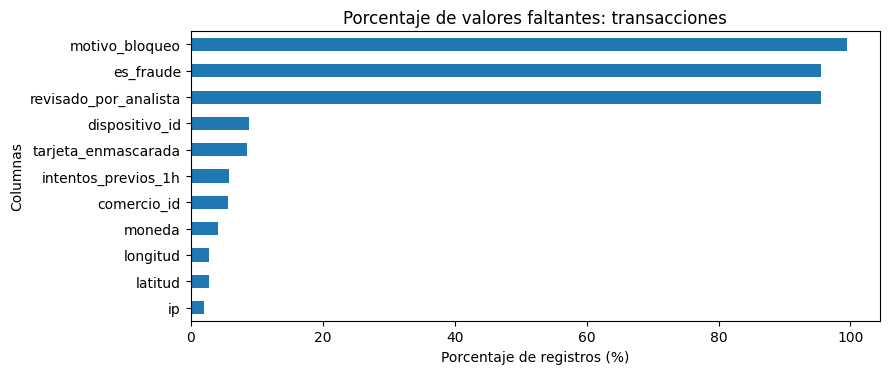


------------------------------------------------------------
Tabla: usuarios


,cantidad_faltante,porcentaje_faltante
nivel_kyc,119,2.36
email_dominio,181,3.59
transacciones_previas,308,6.11
verificado,557,11.06
telefono_verificado,935,18.56


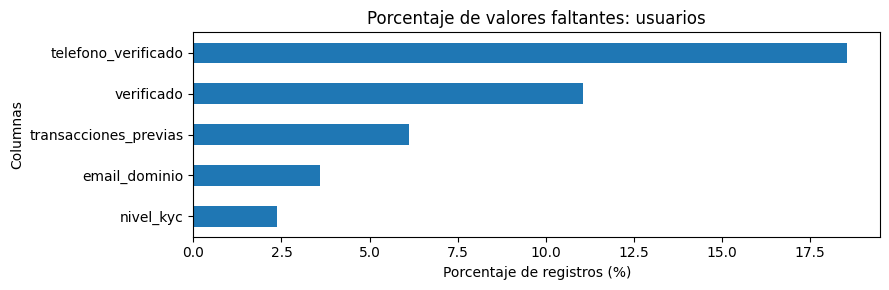


------------------------------------------------------------
Tabla: dispositivos


,cantidad_faltante,porcentaje_faltante
sistema_operativo,721,10.30
emulador,4933,70.47


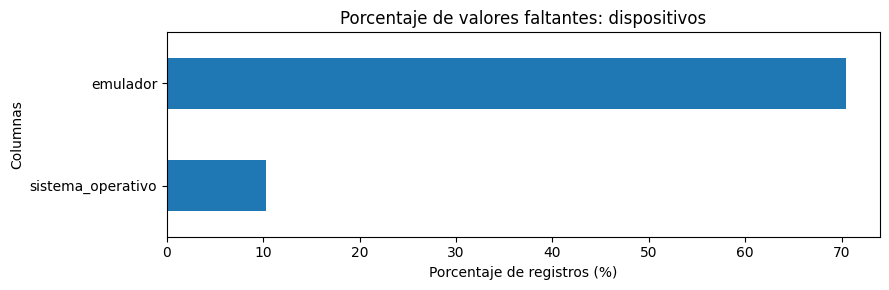


------------------------------------------------------------
Tabla: lista_negra


,cantidad_faltante,porcentaje_faltante
motivo,68,19.43
vigente,74,21.14
agregado_por,94,26.86


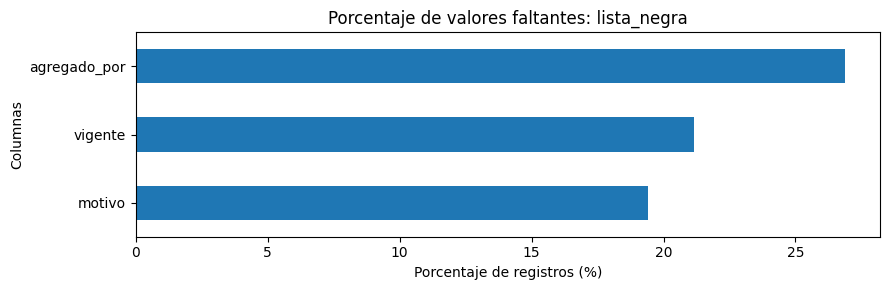

In [13]:
# Resumen general de valores faltantes
resumen_faltantes = []

for nombre, df in datos_limpios.items():
    total_celdas = df.size
    total_faltantes = int(df.isna().sum().sum())

    porcentaje_general = (
        total_faltantes / total_celdas * 100
        if total_celdas > 0 else 0
    )

    resumen_faltantes.append({
        "tabla": nombre,
        "registros": len(df),
        "valores_faltantes": total_faltantes,
        "porcentaje_faltante": round(porcentaje_general, 2)
    })

resumen_faltantes = pd.DataFrame(resumen_faltantes)

print("Resumen general de valores faltantes")
display(resumen_faltantes)

# Detalle de valores faltantes por columna y gráficos
for nombre, df in datos_limpios.items():
    faltantes = df.isna().sum()
    faltantes = faltantes[faltantes > 0].sort_values(ascending=True)

    print("\n" + "-" * 60)
    print(f"Tabla: {nombre}")

    if not faltantes.empty:
        detalle = pd.DataFrame({
            "cantidad_faltante": faltantes,
            "porcentaje_faltante": (
                faltantes / len(df) * 100
            ).round(2)
        })

        display(detalle)

        ax = detalle["porcentaje_faltante"].plot(
            kind="barh",
            figsize=(9, max(3, len(detalle) * 0.35))
        )

        ax.set_title(f"Porcentaje de valores faltantes: {nombre}")
        ax.set_xlabel("Porcentaje de registros (%)")
        ax.set_ylabel("Columnas")

        plt.tight_layout()
        plt.show()

    else:
        print("No hay valores faltantes en esta tabla.")

## **Celda 6: Limpieza y normalización de datos**

### **6.1 Eliminación de duplicados exactos**

In [14]:
print("Eliminación de duplicados exactos")
print("=" * 60)

resumen_duplicados = []

for nombre, df in datos_limpios.items():
    filas_antes = len(df)

    duplicados = df.duplicated().sum()

    datos_limpios[nombre] = df.drop_duplicates().copy()

    filas_despues = len(datos_limpios[nombre])
    eliminados = filas_antes - filas_despues

    resumen_duplicados.append({
        "tabla": nombre,
        "filas_antes": filas_antes,
        "duplicados_exactos": int(duplicados),
        "filas_eliminadas": eliminados,
        "filas_despues": filas_despues
    })

    print(f"\nTabla: {nombre}")
    print(f"Filas iniciales: {filas_antes}")
    print(f"Duplicados exactos: {duplicados}")
    print(f"Filas eliminadas: {eliminados}")
    print(f"Filas finales: {filas_despues}")

resumen_duplicados = pd.DataFrame(resumen_duplicados)

print("\nResumen general")
display(resumen_duplicados)

Eliminación de duplicados exactos

Tabla: transacciones
Filas iniciales: 28421
Duplicados exactos: 97
Filas eliminadas: 97
Filas finales: 28324

Tabla: usuarios
Filas iniciales: 5038
Duplicados exactos: 38
Filas eliminadas: 38
Filas finales: 5000

Tabla: dispositivos
Filas iniciales: 7000
Duplicados exactos: 0
Filas eliminadas: 0
Filas finales: 7000

Tabla: lista_negra
Filas iniciales: 350
Duplicados exactos: 0
Filas eliminadas: 0
Filas finales: 350

Resumen general


,tabla,filas_antes,duplicados_exactos,filas_eliminadas,filas_despues
0,transacciones,28421,97,97,28324
1,usuarios,5038,38,38,5000
2,dispositivos,7000,0,0,7000
3,lista_negra,350,0,0,350


### **6.2 Normalización de categorías**

In [ ]:
print("Normalización de variables categóricas")
print("=" * 60)

#Normalizar texto
columnas_categoricas = {
    "transacciones": [
        "canal",
        "resultado_autorizacion",
        "pais_transaccion"
    ],
    "usuarios": [
        "segmento",
        "pais"
    ],
    "dispositivos": [
        "tipo",
        "pais_declarado"
    ],
    "lista_negra": [
        "tipo",
        "motivo"
    ]
}

for tabla, columnas in columnas_categoricas.items():
    if tabla not in datos_limpios:
        continue

    df = datos_limpios[tabla]

    for columna in columnas:
        if columna in df.columns:
            df[columna] = (
                df[columna].astype("string").str.strip().str.lower()
            )

            df[columna] = df[columna].replace("", pd.NA)

    datos_limpios[tabla] = df


Dataset: transacciones

canal:
canal
app            11393
web             8495
pos             5136
api             1703
movil           1088
punto_venta      509
Name: count, dtype: Int64

resultado_autorizacion:
resultado_autorizacion
aprobada     25310
rechazada     2476
pendiente      538
Name: count, dtype: Int64

Dataset: usuarios

segmento:
segmento
persona             3713
comercio_pequeno     535
individuo            421
comercio_grande      152
comercio pequeño      71
pyme                  71
comercio grande       21
empresa               16
Name: count, dtype: Int64

Dataset: dispositivos

tipo:
tipo
android    3225
ios        1965
web        1395
pos         415
Name: count, dtype: Int64

Dataset: lista_negra

tipo:
tipo
ip             133
dispositivo    113
comercio        60
tarjeta         44
Name: count, dtype: Int64

motivo:
motivo
<NA>                      68
revisar                   64
fraude_confirmado         60
reporte_comercio          54
solicitud_cumplimient

In [ ]:
#Unificar categorías de tipo de dispositivo
if "dispositivos" in datos_limpios:
    df = datos_limpios["dispositivos"].copy()

    if "tipo" in df.columns:
        print("Distribución de tipos de dispositivos")
        display(
            df["tipo"]
            .value_counts(dropna=False)
            .to_frame("frecuencia")
        )

    datos_limpios["dispositivos"] = df

In [ ]:
#Unificar categorías de segmentos de usuarios
if "usuarios" in datos_limpios:
    df = datos_limpios["usuarios"].copy()

    if "segmento" in df.columns:
        df["segmento"] = df["segmento"].replace({
            "individuo": "persona",
            "comercio pequeño": "comercio_pequeno",
            "comercio grande": "comercio_grande"
        })

        print("Distribución de segmentos de usuarios:")
        display(
            df["segmento"]
            .value__counts(dropna=False)
            .to_frame("frecuencia")
        )

    datos_limpios["usuarios"] = df

In [ ]:
#Normalizar nombres de países mediante equivalencias
equivalencias_paises = {
    "chile": "CL",
    "chile (cl)": "CL",
    "argentina": "AR",
    "argentina (ar)": "AR",
    "peru": "PE",
    "perú": "PE",
    "peru (pe)": "PE",
    "brasil": "BR",
    "brazil": "BR",
    "brasil (br)": "BR",
    "estados unidos": "US",
    "united states": "US",
    "usa": "US",
    "ee.uu.": "US",
    "mexico": "MX",
    "méxico": "MX",
    "colombia": "CO",
    "uruguay": "UY",
    "paraguay" : "PY",
    "bolivia": "BO"
}

columnas_paises = {
    "transacciones": "pais_transaccion",
    "usuarios": "pais",
    "dispositivos": "pais_declarado"
}

for tabla, columna in columnas_paises.items():
    if tabla not in datos_limpios:
        continue

    df = datos_limpios[tabla].copy()

    if columna in df.columns:
        df[columna] = df[columna].replace(equivalencias_paises)

        print(f"\nPaíses normalizados en {tabla}:")
        display(
            df[columna]
            .value_counts(dropns=False)
            .to_frame("frecuencia")
        )

    datos_limpios[tabla] = df

In [ ]:
#Revisar resultados de la normalización
for tabla, columnas in columnas_categoricas.items():
    if tabla not in datos_limpios:
        continue

    df = datos_limpios[tabla]

    print(f"\nTabla: {tabla}")

    for columna in columnas:
        if columna in df.columns:
            print(f"\nValores únicos de '{columna}':")
            display(
                df[columna]
                .value_counts(dropna=False)
                .head(20)
                .to_frame("frecuencia")
            )

print("\nLa normalización categórica ya terminó btw")

### **6.3 Limpieza y normalización de montos**

In [ ]:
if "transacciones" in datos_limpios:
    df = datos_limpios["transacciones"].copy()

    if "monto" in df.columns:

        # Conservar el monto original
        if "monto_original" not in df.columns:
            df["monto_original"] = df["monto"].copy()

        # Normalizar códigos de moneda
        equivalencias_moneda = {
            "$": "CLP",
            "PESO": "CLP",
            "PESOS": "CLP",
            "CLP": "CLP",
            "USD": "USD",
            "US$": "USD",
            "DOLAR": "USD",
            "DÓLAR": "USD",
            "DOLARES": "USD",
            "DÓLARES": "USD"
        }

        if "moneda" in df.columns:
            df["moneda"] = (
                df["moneda"]
                .astype("string")
                .str.strip()
                .str.upper()
            )

            df["moneda"] = df["moneda"].replace(
                equivalencias_moneda
            )
        else:
            df["moneda"] = pd.NA

        # Función para interpretar montos
        def interpretar_montos(valor, moneda):

            if pd.isna(valor) or pd.isna(moneda):
                return pd.NA, True

            moneda = str(moneda).strip().upper()

            if moneda not in ["CLP", "USD"]:
                return pd.NA, True

            texto = str(valor).strip()

            if texto == "":
                return pd.NA, True

            texto = texto.replace("$", "")
            texto = texto.replace(" ", "")

            # Permitir montos negativos
            if texto.startswith("-"):
                signo = "-"
                texto = texto[1:]
            else:
                signo = ""

            if not texto:
                return pd.NA, True

            # Validar caracteres
            if not all(c.isdigit() or c in ".," for c in texto):
                return pd.NA, True

            # Montos sin separadores
            if "." not in texto and "," not in texto:
                try:
                    return float(signo + texto), False
                except ValueError:
                    return pd.NA, True

            # Interpretación de montos CLP
            if moneda == "CLP":

                if "." in texto and "," not in texto:
                    partes = texto.split(".")
                elif "," in texto and "." not in texto:
                    partes = texto.split(",")
                else:
                    return pd.NA, True

                # Separadores de miles con grupos de 3 dígitos
                if (
                    len(partes) >= 2
                    and partes[0].isdigit()
                    and all(
                        parte.isdigit() and len(parte) == 3
                        for parte in partes[1:]
                    )
                ):
                    numero = "".join(partes)

                    try:
                        return float(signo + numero), False
                    except ValueError:
                        return pd.NA, True

                return pd.NA, True

            # Interpretación de montos USD
            if moneda == "USD":

                if texto.count(".") + texto.count(",") == 1:
                    separador = "." if "." in texto else ","
                    partes = texto.split(separador)

                    if (
                        len(partes) == 2
                        and partes[0].isdigit()
                        and partes[1].isdigit()
                        and 1 <= len(partes[1]) <= 2
                    ):
                        numero = partes[0] + "." + partes[1]

                        try:
                            return float(signo + numero), False
                        except ValueError:
                            return pd.NA, True

                return pd.NA, True

            return pd.NA, True

        # Aplicar normalización
        resultados = df.apply(
            lambda fila: interpretar_montos(
                fila["monto_original"],
                fila["moneda"]
            ),
            axis=1
        )

        df["monto_normalizado"] = pd.array(
            [resultado[0] for resultado in resultados],
            dtype="Float64"
        )

        df["monto_ambiguo"] = [
            resultado[1] for resultado in resultados
        ]

        # Identificar monedas desconocidas
        df["moneda_desconocida"] = (
            df["moneda"].isna()
            | ~df["moneda"].isin(["CLP", "USD"])
        )

        # Identificar montos negativos y en cero
        df["monto_negativo"] = (
            df["monto_normalizado"] < 0
        ).fillna(False)

        df["monto_cero"] = (
            df["monto_normalizado"] == 0
        ).fillna(False)

        # Resumen de resultados
        print("-" * 60)
        print("RESUMEN DE NORMALIZACIÓN DE MONTOS")
        print("-" * 60)

        print("Total de transacciones:", len(df))
        print("Montos normalizados:", df["monto_normalizado"].notna().sum())
        print("Montos ambiguos:", df["monto_ambiguo"].sum())
        print("Monedas desconocidas:", df["moneda_desconocida"].sum())
        print("Montos negativos:", df["monto_negativo"].sum())
        print("Montos en cero:", df["monto_cero"].sum())

        print("\nDistribución de monedas:")
        display(
            df["moneda"]
            .value_counts(dropna=False)
            .to_frame("frecuencia")
        )

        print("\nEjemplos de montos normalizados:")
        display(
            df[
                [
                    "monto_original",
                    "moneda",
                    "monto_normalizado",
                    "monto_ambiguo"
                ]
            ].head(15)
        )

        # Guardar los cambios
        datos_limpios["transacciones"] = df

    else:
        print("No se encontró la columna 'monto'.")

### **6.5 Limpieza de montos y monedas**

#### **6.5.1 Conservar montos originales**

In [ ]:
# Guardar una copia de los montos originales
datos_limpios["transacciones"]["monto_original"] = (
  datos_limpios["transacciones"]["monto"].copy()
)

print("Montos originales conservados correctamente.")

# Verificar que se conservaron los valores
display(
  datos_limpios["transacciones"][
    ["monto", "monto_original", "moneda"]
  ].head(10)
)

Montos originales conservados correctamente.


,monto,monto_original,moneda
0,$9,$9,USD
1,261293,261293,CLP
2,2284,2284,CLP
3,3653,3653,CLP
4,$37,$37,USD
5,44974,44974,CLP
6,2681,2681,CLP
7,"6,36","6,36",USD
8,1996,1996,CLP
9,8958,8958,CLP


#### **6.5.2 Diagnóstico de formatos numéricos**

In [ ]:
# No ejecutar hasta después papáDio pt2

tx = datos_limpios["transacciones"]

# Revisar formatos de montos por moneda
for moneda in ["CLP", "USD"]:
  montos = tx.loc[
    tx["moneda"] == moneda, "monto_original"
  ].astype("string").str.strip()

  print(f"\nMoneda: {moneda}")
  print("Valores con coma:", montos.str.contains(",", na=False).sum())
  print("Valores con punto:", montos.str.contains(r"\.", na=False).sum())
  print("Valores sin separador:", (~montos.str.contains(r"[,.]", na=False)).sum())

# Revisar montos sin moneda
montos_sin_moneda = tx.loc[tx["moneda"].isna(), "monto_original"]

print("\nEjemplos de montos sin moneda:")
print(montos_sin_moneda.head(20).to_list())


Moneda: CLP
Valores con coma: 0
Valores con punto: 6039
Valores sin separador: 17823

Moneda: USD
Valores con coma: 243
Valores con punto: 2389
Valores sin separador: 668

Ejemplos de montos sin moneda:
['4658', '$22.214', '1.666', '7390', '35061', '232.359', '3.60', '$4.341', '1.653', '5.310', '$1.383', '8882', '38233', '7797', '30276', '9.41', '38069', '41.93', '-40276', '6602']


#### **6.5.3 Revisar las monedas**

In [ ]:
tx = datos_limpios["transacciones"]

# Normalizar los códigos de moneda
tx["moneda"] = (
  tx["moneda"]
  .astype("string")
  .str.strip()
  .str.upper()
)

# Revisar distribución de monedas
print("Distribución de monedas:")
print(tx["moneda"].value_counts(dropna=False))

# Revisar montos originales por moneda
tx_original = datos_originales["transacciones"]

for moneda in ["CLP", "USD"]:
  indices = tx.index[tx["moneda"] == moneda]

  print(f"\nEjemplos de montos en {moneda}:")
  print(tx_original.loc[indices[:10], "monto"].to_list())

# Revisar montos sin moneda
indices_sin_moneda = tx.index[tx["moneda"].isna()]

print("\nEjemplos de montos sin moneda:")
print(tx_original.loc[indices_sin_moneda[:30],["transaccion_id", "monto"]])

Distribución de monedas:
moneda
CLP     23862
USD      3300
<NA>     1162
Name: count, dtype: Int64

Ejemplos de montos en CLP:
['261293', '2284', '3653', '44974', '2681', '1996', '8958', '8.199', '19953', '14677']

Ejemplos de montos en USD:
['$9', '$37', '6,36', '$35', '47.33', '4.59', '11,17', '5', '7.61', '6.57']

Ejemplos de montos sin moneda:
    transaccion_id    monto
40       TX7009640     4658
122      TX7012956  $22.214
160      TX7019754    1.666
166      TX7001687     7390
334      TX7021864    35061
367      TX7002497  232.359
377      TX7021729     3.60
399      TX7014724   $4.341
400      TX7009457    1.653
407      TX7015207    5.310
495      TX7017126   $1.383
497      TX7007136     8882
510      TX7010961    38233
526      TX7026868     7797
547      TX7028189    30276
573      TX7017546     9.41
623      TX7002605    38069
633      TX7003701    41.93
641      TX7022351   -40276
657      TX7005705     6602
673      TX7010531   $2.609
715      TX7016439   170018
719  

In [ ]:
tx = datos_limpios["transacciones"]

# Recuperar los montos originales
texto = (
    tx["monto_original"]
    .astype("string")
    .str.strip()
    .str.replace("$", "", regex=False)
)

# Identificar separadores de miles en CLP
patron_miles = r"^-?\d{1,3}\.\d{3}$"

clp_miles = (
    tx["moneda"].eq("CLP").fillna(False)
    & texto.str.fullmatch(patron_miles).fillna(False)
)

# Corregir miles en CLP
texto.loc[clp_miles] = (
    texto.loc[clp_miles]
    .str.replace(".", "", regex=False)
)

# Corregir comas decimales
texto = texto.str.replace(",", ".", regex=False)

# Convertir toda la columna a números
tx["monto"] = pd.to_numeric(
    texto,
    errors="coerce"
).astype("Float64")

# Validar
print("=== VALIDACIÓN DE MONTOS ===")
print("Tipo de dato:", tx["monto"].dtype)
print("Montos nulos:", tx["monto"].isna().sum())
print("Montos CLP con miles corregidos:", clp_miles.sum())
print("Montos negativos:", (tx["monto"] < 0).sum())
print("Montos iguales a cero:", (tx["monto"] == 0).sum())

=== VALIDACIÓN DE MONTOS ===
Tipo de dato: Float64
Montos nulos: 0
Montos CLP con miles corregidos: 6039
Montos negativos: 250
Montos iguales a cero: 352


#### **6.5.4 Identificar formatos numéricos ambiguos**

In [ ]:
tx = datos_limpios["transacciones"]

# Analizar el formato original, sin modificar los montos
montos_texto = (
  tx["monto_original"]
  .astype("string")
  .str.strip()
  .str.replace("$", "", regex=False)
)

# Valores terminados en punto o coma y tres dígitos
patron_ambiguo = r"^-?\d{1,3}[.,]\d{3}$"

ambiguos = tx[montos_texto.str.fullmatch(patron_ambiguo).fillna(False)]

print("Montos con formato ambiguo:", len(ambiguos))

print("\nDistribución por moneda:")
print(ambiguos["moneda"].value_counts(dropna=False))

print("\nEjemplos:")
display(
  ambiguos[
    ["monto_original", "monto", "moneda"]
  ].head(15)
)

print("\nMontos negativos:", (tx["monto"] < 0).sum())
print("Montos iguales a cero:", (tx["monto"] == 0).sum())

Montos con formato ambiguo: 6276

Distribución por moneda:
moneda
CLP     6039
<NA>     237
Name: count, dtype: Int64

Ejemplos:


,monto_original,monto,moneda
10,8.199,8199.0,CLP
20,10.535,10535.0,CLP
22,8.514,8514.0,CLP
29,$1.265,1265.0,CLP
34,$6.127,6127.0,CLP
44,3.956,3956.0,CLP
46,7.446,7446.0,CLP
48,4.915,4915.0,CLP
55,$1.636,1636.0,CLP
62,$18.097,18097.0,CLP



Montos negativos: 250
Montos iguales a cero: 352


#### **6.5.5 Corregir separadores de miles en CLP**

In [ ]:
tx = datos_limpios["transacciones"]

# Recuperar representación original
texto_original = (
  tx["monto_original"]
  .astype("string")
  .str.strip()
  .str.replace("$", "", regex=False)
)

# Identificar CLP con un punto seguido de tres dígitos
patron_miles = r"^-?\d{1,3}\.\d{3}$"

corregir_clp = (
  tx["moneda"].eq("CLP").fillna(False)
  & texto_original.str.fullmatch(patron_miles).fillna(False)
)

# Corregir puntos utilizados como separadores de miles
cantidad = corregir_clp.sum()

tx.loc[corregir_clp, "monto"] = pd.to_numeric(
  texto_original.loc[corregir_clp].str.replace(
    ".", "", regex=False
  ),
  errors="coerce"
)

print("Montos CLP corregidos:", cantidad)

print("\nEjemplos corregidos:")
display(
  tx.loc[
    corregir_clp,
    ["monto_original", "monto", "moneda"]
  ].head(10)
)

Montos CLP corregidos: 6039

Ejemplos corregidos:


,monto_original,monto,moneda
10,8.199,8199.0,CLP
20,10.535,10535.0,CLP
22,8.514,8514.0,CLP
29,$1.265,1265.0,CLP
34,$6.127,6127.0,CLP
44,3.956,3956.0,CLP
46,7.446,7446.0,CLP
48,4.915,4915.0,CLP
55,$1.636,1636.0,CLP
62,$18.097,18097.0,CLP


#### **6.5.6 Identificar montos sin moneda**

In [ ]:
tx = datos_limpios["transacciones"]

# Crear indicador de moneda desconocida
tx["moneda_desconocida"] = tx["moneda"].isna().astype(int)

# Marcar montos con formato ambiguo y moneda desconocida
texto_original = (
    tx["monto_original"]
    .astype("string")
    .str.strip()
    .str.replace("$", "", regex=False)
)

patron_ambiguo = r"^-?\d{1,3}[.,]\d{3}$"

tx["monto_ambiguo"] = (
    tx["moneda"].isna().fillna(False)
    & texto_original.str.fullmatch(patron_ambiguo).fillna(False)
).astype(int)

print("Transacciones sin moneda:",
      tx["moneda_desconocida"].sum())

print("Montos ambiguos sin moneda:",
      tx["monto_ambiguo"].sum())

print("\nResumen:")
print(
    tx[["moneda_desconocida", "monto_ambiguo"]]
    .value_counts()
)

print("\nTotal de registros:", len(tx))

Transacciones sin moneda: 1162
Montos ambiguos sin moneda: 237

Resumen:
moneda_desconocida  monto_ambiguo
0                   0                27162
1                   0                  925
                    1                  237
Name: count, dtype: int64

Total de registros: 28324


#### **6.5.7 Identificar montos negativos y montos iguales a cero**

In [ ]:
tx = datos_limpios["transacciones"]

# Identificar montos problemáticos
tx["monto_negativo"] = (tx["monto"] < 0).astype(int)
tx["monto_cero"] = (tx["monto"] == 0).astype(int)

print("Montos negativos:", tx["monto_negativo"].sum())
print("Montos iguales a cero:", tx["monto_cero"].sum())

print("\nDistribución de montos negativos por moneda:")
print(
    tx.loc[tx["monto_negativo"] == 1, "moneda"]
    .value_counts(dropna=False)
)

print("\nEjemplos de montos negativos:")
print(
    tx.loc[
        tx["monto_negativo"] == 1,
        ["transaccion_id", "monto_original", "monto",
         "moneda", "resultado_autorizacion"]
    ].head(10)
)

print("\nTotal de transacciones:", len(tx))

Montos negativos: 250
Montos iguales a cero: 352

Distribución de montos negativos por moneda:
moneda
CLP     208
USD      33
<NA>      9
Name: count, dtype: Int64

Ejemplos de montos negativos:
     transaccion_id monto_original     monto moneda resultado_autorizacion
58        TX7021747          -7325   -7325.0    CLP               aprobada
234       TX7026004          -4799   -4799.0    CLP               aprobada
424       TX7026548             -5      -5.0    USD               aprobada
603       TX7019956          -7438   -7438.0    CLP               aprobada
641       TX7022351         -40276  -40276.0   <NA>               aprobada
1200      TX7021220          -1576   -1576.0    CLP              rechazada
1241      TX7016178          -7073   -7073.0    CLP               aprobada
1309      TX7025954          -1218   -1218.0    CLP               aprobada
1535      TX7001716          -3737   -3737.0    CLP               aprobada
1538      TX7007977        -181525 -181525.0    CLP    

#### **6.5.8 Resumen de la división de montos y monedas**

In [ ]:
tx = datos_limpios["transacciones"]

print("=== RESUMEN DE MONTOS Y MONEDAS ===")

print("Total de transacciones:", len(tx))
print("Montos nulos:", tx["monto"].isna().sum())
print("Monedas desconocidas:", tx["moneda_desconocida"].sum())
print("Montos ambiguos:", tx["monto_ambiguo"].sum())
print("Montos negativos:", tx["monto_negativo"].sum())
print("Montos iguales a cero:", tx["monto_cero"].sum())

print("\nTipos de datos:")
print(tx[["monto", "moneda"]].dtypes)

print("\nDistribución final de monedas:")
print(tx["moneda"].value_counts(dropna=False))

=== RESUMEN DE MONTOS Y MONEDAS ===
Total de transacciones: 28324
Montos nulos: 0
Monedas desconocidas: 1162
Montos ambiguos: 237
Montos negativos: 250
Montos iguales a cero: 352

Tipos de datos:
monto            Float64
moneda    string[python]
dtype: object

Distribución final de monedas:
moneda
CLP     23862
USD      3300
<NA>     1162
Name: count, dtype: Int64


### **6.6. Normalización de fechas**

#### **6.6.1. Identificar los formatos de fecha**

In [ ]:
columnas_fechas = {
    "transacciones": "timestamp",
    "usuarios": "fecha_registro",
    "dispositivos": "primera_vez",
    "lista_negra": "fecha_alta"
}

for nombre, columna in columnas_fechas.items():

    df = datos_limpios[nombre]

    print(f"\n{'=' * 50}")
    print(f"Dataset: {nombre}")
    print(f"Columna: {columna}")

    print("\nTipo de dato:")
    print(df[columna].dtype)

    print("\nValores faltantes:")
    print(df[columna].isna().sum())

    print("\nEjemplos de fechas:")
    print(df[columna].dropna().head(10).tolist())


Dataset: transacciones
Columna: timestamp

Tipo de dato:
object

Valores faltantes:
0

Ejemplos de fechas:
['2026-01-12T14:48:02Z', '2025-10-23 18:24:22', '2024-01-19T01:36:58Z', '2024-09-11T10:26:05Z', '2024-11-19 23:33:30', '2026-03-07 06:33:51-04:00', '2026-07-04T16:28:07Z', '2026-05-09 06:19:01', '2025-03-19T03:28:00Z', '2025-11-03 21:42:27']

Dataset: usuarios
Columna: fecha_registro

Tipo de dato:
object

Valores faltantes:
0

Ejemplos de fechas:
['30/06/2018', '20-02-2025', '2023-10-25', '09-12-2024', '08/04/2020', '03/02/2026', '07-01-2023', '2018-07-18', '2025-10-10', '10-08-2018']

Dataset: dispositivos
Columna: primera_vez

Tipo de dato:
object

Valores faltantes:
0

Ejemplos de fechas:
['2025-02-17T19:07:56Z', '2024-12-30 20:56:16-04:00', '2019-02-20T09:59:38Z', '2019-07-04 16:47:17', '2025-02-19 18:32:57', '2020-10-24 12:38:51', '2025-06-23 09:07:38', '13/12/2025 02:37', '2026-06-03T08:13:18Z', '2025-01-17T12:52:46Z']

Dataset: lista_negra
Columna: fecha_alta

Tipo de dat

#### **6.6.2. Normalizar fechas de usuarios y lista negra**

In [ ]:
def normalizar_fecha(fecha):

    if pd.isna(fecha):
        return pd.NaT

    fecha = str(fecha).strip()

    # Fechas en formato YYYY-MM-DD
    if fecha[:4].isdigit() and fecha[4:5] == "-":
        return pd.to_datetime(fecha, format="%Y-%m-%d", errors="coerce")

    # Fechas en formato DD/MM/YYYY
    if "/" in fecha:
        return pd.to_datetime(fecha, format="%d/%m/%Y", errors="coerce")

    # Fechas en formato DD-MM-YYYY
    return pd.to_datetime(fecha, format="%d-%m-%Y", errors="coerce")


columnas = {
    "usuarios": "fecha_registro",
    "lista_negra": "fecha_alta"
}

for nombre, columna in columnas.items():

    df = datos_limpios[nombre]

    # Conservar la fecha original
    df[f"{columna}_original"] = df[columna].copy()

    # Convertir fechas
    df[columna] = pd.to_datetime(
        df[columna].apply(normalizar_fecha),
        errors="coerce"
    )

    print(f"\nDataset: {nombre}")
    print("Tipo de dato:", df[columna].dtype)
    print("Fechas no convertidas:", df[columna].isna().sum())

    print("\nEjemplos:")
    print(
        df[[f"{columna}_original", columna]].head(10)
    )


Dataset: usuarios
Tipo de dato: datetime64[ns]
Fechas no convertidas: 0

Ejemplos:
  fecha_registro_original fecha_registro
0              30/06/2018     2018-06-30
1              20-02-2025     2025-02-20
2              2023-10-25     2023-10-25
3              09-12-2024     2024-12-09
4              08/04/2020     2020-04-08
5              03/02/2026     2026-02-03
6              07-01-2023     2023-01-07
7              2018-07-18     2018-07-18
8              2025-10-10     2025-10-10
9              10-08-2018     2018-08-10

Dataset: lista_negra
Tipo de dato: datetime64[ns]
Fechas no convertidas: 0

Ejemplos:
  fecha_alta_original fecha_alta
0          2020-12-10 2020-12-10
1          18/06/2019 2019-06-18
2          2021-10-16 2021-10-16
3          2021-12-04 2021-12-04
4          01/05/2025 2025-05-01
5          2020-10-12 2020-10-12
6          26/09/2019 2019-09-26
7          19/02/2025 2025-02-19
8          19/06/2022 2022-06-19
9          2023-01-27 2023-01-27


#### **6.6.3. Normalización de timestamps de transacciones y dispositivos**

In [ ]:
columnas_timestamps = {
    "transacciones": "timestamp",
    "dispositivos": "primera_vez"
}

for nombre, columna in columnas_timestamps.items():

    df = datos_limpios[nombre]

    # Conservar valores originales
    df[f"{columna}_original"] = df[columna].copy()

    fechas = df[columna].astype("string").str.strip()

    # Identificar fechas que tienen zona horaria explícita
    tiene_zona = fechas.str.contains(
        r"(?:Z|[+-]\d{2}:\d{2})$",
        regex=True,
        na=False
    )

    df[f"{columna}_tiene_zona"] = tiene_zona

    print(f"\nDataset: {nombre}")
    print("Total de registros:", len(df))
    print("Fechas con zona horaria:", tiene_zona.sum())
    print("Fechas sin zona horaria:", (~tiene_zona).sum())

    print("\nEjemplos sin zona horaria:")
    print(
        df.loc[~tiene_zona, [columna]]
        .head(5)
    )


Dataset: transacciones
Total de registros: 28324
Fechas con zona horaria: 11864
Fechas sin zona horaria: 16460

Ejemplos sin zona horaria:
              timestamp
1   2025-10-23 18:24:22
4   2024-11-19 23:33:30
7   2026-05-09 06:19:01
9   2025-11-03 21:42:27
10     22/11/2024 20:53

Dataset: dispositivos
Total de registros: 7000
Fechas con zona horaria: 3005
Fechas sin zona horaria: 3995

Ejemplos sin zona horaria:
           primera_vez
3  2019-07-04 16:47:17
4  2025-02-19 18:32:57
5  2020-10-24 12:38:51
6  2025-06-23 09:07:38
7     13/12/2025 02:37


#### **6.6.4. Normalización de timestamps de transacciones y dispositivos**

In [ ]:
def convertir_timestamp_utc(valor):
    if pd.isna(valor):
        return pd.NaT

    texto = str(valor).strip()

    # Solo convertir fechas con zona horaria explícita
    if not re.search(r"(?:Z|[+-]\d{2}:\d{2})$", texto):
        return pd.NaT

    return pd.to_datetime(
        texto,
        utc=True,
        errors="coerce"
    )


columnas_timestamps = {
    "transacciones": "timestamp",
    "dispositivos": "primera_vez"
}

for nombre, columna in columnas_timestamps.items():

    df = datos_limpios[nombre]

    # Crear nueva columna UTC
    df[f"{columna}_utc"] = pd.to_datetime(
        df[columna].apply(convertir_timestamp_utc),
        utc=True,
        errors="coerce"
    )

    tiene_zona = df[f"{columna}_tiene_zona"]

    print(f"\nDataset: {nombre}")
    print("Fechas con zona explícita:", tiene_zona.sum())

    print(
        "Fechas convertidas correctamente:",
        df.loc[tiene_zona, f"{columna}_utc"].notna().sum()
    )

    print(
        "Fechas con zona que fallaron:",
        df.loc[tiene_zona, f"{columna}_utc"].isna().sum()
    )

    print(
        "Fechas pendientes por zona desconocida:",
        (~tiene_zona).sum()
    )

    print("\nEjemplos:")
    print(
        df.loc[
            tiene_zona,
            [f"{columna}_original", f"{columna}_utc"]
        ].head(5)
    )


Dataset: transacciones
Fechas con zona explícita: 11864
Fechas convertidas correctamente: 11864
Fechas con zona que fallaron: 0
Fechas pendientes por zona desconocida: 16460

Ejemplos:
          timestamp_original             timestamp_utc
0       2026-01-12T14:48:02Z 2026-01-12 14:48:02+00:00
2       2024-01-19T01:36:58Z 2024-01-19 01:36:58+00:00
3       2024-09-11T10:26:05Z 2024-09-11 10:26:05+00:00
5  2026-03-07 06:33:51-04:00 2026-03-07 10:33:51+00:00
6       2026-07-04T16:28:07Z 2026-07-04 16:28:07+00:00

Dataset: dispositivos
Fechas con zona explícita: 3005
Fechas convertidas correctamente: 3005
Fechas con zona que fallaron: 0
Fechas pendientes por zona desconocida: 3995

Ejemplos:
        primera_vez_original           primera_vez_utc
0       2025-02-17T19:07:56Z 2025-02-17 19:07:56+00:00
1  2024-12-30 20:56:16-04:00 2024-12-31 00:56:16+00:00
2       2019-02-20T09:59:38Z 2019-02-20 09:59:38+00:00
8       2026-06-03T08:13:18Z 2026-06-03 08:13:18+00:00
9       2025-01-17T12:52:46

#### **6.6.5. Normalizar fechas sin zona horaria**

In [ ]:
def convertir_fecha_sin_zona(valor):

    if pd.isna(valor):
        return pd.NaT

    texto = str(valor).strip()

    # Formato DD/MM/YYYY HH:MM o HH:MM:SS
    if "/" in texto:
        return pd.to_datetime(
            texto,
            dayfirst=True,
            errors="coerce"
        )

    # Formato YYYY-MM-DD HH:MM:SS
    return pd.to_datetime(
        texto,
        format="%Y-%m-%d %H:%M:%S",
        errors="coerce"
    )


columnas_timestamps = {
    "transacciones": "timestamp",
    "dispositivos": "primera_vez"
}

for nombre, columna in columnas_timestamps.items():

    df = datos_limpios[nombre]

    sin_zona = ~df[f"{columna}_tiene_zona"]

    nueva_columna = f"{columna}_sin_zona"

    # Crear columna sin asignar zona horaria
    df[nueva_columna] = pd.NaT

    df.loc[sin_zona, nueva_columna] = pd.to_datetime(
        df.loc[sin_zona, columna].apply(convertir_fecha_sin_zona),
        errors="coerce"
    )

    print(f"\nDataset: {nombre}")

    print("Fechas sin zona originales:", sin_zona.sum())

    print(
        "Fechas sin zona convertidas:",
        df.loc[sin_zona, nueva_columna].notna().sum()
    )

    print(
        "Fechas que fallaron:",
        df.loc[sin_zona, nueva_columna].isna().sum()
    )

    print("\nEjemplos:")
    print(
        df.loc[
            sin_zona,
            [f"{columna}_original", nueva_columna]
        ].head(5)
    )


Dataset: transacciones
Fechas sin zona originales: 16460
Fechas sin zona convertidas: 16460
Fechas que fallaron: 0

Ejemplos:
     timestamp_original  timestamp_sin_zona
1   2025-10-23 18:24:22 2025-10-23 18:24:22
4   2024-11-19 23:33:30 2024-11-19 23:33:30
7   2026-05-09 06:19:01 2026-05-09 06:19:01
9   2025-11-03 21:42:27 2025-11-03 21:42:27
10     22/11/2024 20:53 2024-11-22 20:53:00

Dataset: dispositivos
Fechas sin zona originales: 3995
Fechas sin zona convertidas: 3995
Fechas que fallaron: 0

Ejemplos:
  primera_vez_original primera_vez_sin_zona
3  2019-07-04 16:47:17  2019-07-04 16:47:17
4  2025-02-19 18:32:57  2025-02-19 18:32:57
5  2020-10-24 12:38:51  2020-10-24 12:38:51
6  2025-06-23 09:07:38  2025-06-23 09:07:38
7     13/12/2025 02:37  2025-12-13 02:37:00


#### **6.6.6. Validación final de fechas**

In [ ]:
columnas_timestamps = {
    "transacciones": "timestamp",
    "dispositivos": "primera_vez"
}

for nombre, columna in columnas_timestamps.items():

    df = datos_limpios[nombre]

    fecha_utc = df[f"{columna}_utc"]
    fecha_sin_zona = df[f"{columna}_sin_zona"]

    # Verificar cobertura de fechas normalizadas
    fechas_validas = fecha_utc.notna() | fecha_sin_zona.notna()

    # Detectar registros con ambas representaciones
    fechas_duplicadas = fecha_utc.notna() & fecha_sin_zona.notna()

    print(f"\n{'=' * 45}")
    print(f"Dataset: {nombre}")
    print("Total de registros:", len(df))
    print("Fechas normalizadas:", fechas_validas.sum())
    print("Fechas sin normalizar:", (~fechas_validas).sum())
    print("Fechas con ambas representaciones:", fechas_duplicadas.sum())

    print("\nRango de fechas UTC:")
    print("Mínima:", fecha_utc.min())
    print("Máxima:", fecha_utc.max())

    print("\nRango de fechas sin zona:")
    print("Mínima:", fecha_sin_zona.min())
    print("Máxima:", fecha_sin_zona.max())


Dataset: transacciones
Total de registros: 28324
Fechas normalizadas: 28324
Fechas sin normalizar: 0
Fechas con ambas representaciones: 0

Rango de fechas UTC:
Mínima: 2023-08-01 05:04:58+00:00
Máxima: 2026-08-01 02:27:22+00:00

Rango de fechas sin zona:
Mínima: 2023-08-01 07:07:08
Máxima: 2026-07-31 19:55:34

Dataset: dispositivos
Total de registros: 7000
Fechas normalizadas: 7000
Fechas sin normalizar: 0
Fechas con ambas representaciones: 0

Rango de fechas UTC:
Mínima: 2019-01-01 11:05:41+00:00
Máxima: 2026-08-01 01:10:23+00:00

Rango de fechas sin zona:
Mínima: 2019-01-02 11:59:45
Máxima: 2026-07-30 11:12:57


### **6.7. Tratamiento de valores faltantes e inválidos**

#### **6.7.1. Diagnóstico de valores faltantes**

In [ ]:
for nombre, df in datos_limpios.items():

    print(f"\n{'=' * 50}")
    print(f"Dataset: {nombre}")
    print(f"Total de registros: {len(df)}")

    resumen = pd.DataFrame({
        "Nulos": df.isna().sum(),
        "Porcentaje (%)": (
            df.isna().sum() / len(df) * 100
        ).round(2)
    })

    # Mostrar solamente columnas con valores faltantes
    resumen = resumen[resumen["Nulos"] > 0]

    print("\nColumnas con valores faltantes:")

    if resumen.empty:
        print("No se encontraron valores faltantes.")
    else:
        print(resumen.sort_values("Porcentaje (%)", ascending=False))


Dataset: transacciones
Total de registros: 28324

Columnas con valores faltantes:
                       Nulos  Porcentaje (%)
motivo_bloqueo         28182           99.50
revisado_por_analista  27069           95.57
es_fraude              27069           95.57
timestamp_utc          16460           58.11
timestamp_sin_zona     11864           41.89
dispositivo_id          2526            8.92
tarjeta_enmascarada     2407            8.50
intentos_previos_1h     1664            5.87
comercio_id             1612            5.69
moneda                  1162            4.10
latitud                  786            2.78
longitud                 786            2.78
ip                       593            2.09

Dataset: usuarios
Total de registros: 5000

Columnas con valores faltantes:
                       Nulos  Porcentaje (%)
telefono_verificado      925           18.50
verificado               552           11.04
transacciones_previas    307            6.14
email_dominio            179  

#### **6.7.2. Revisar los valores faltantes de variables críticas**

In [ ]:
columnas_revision = {
    "transacciones": [
        "es_fraude",
        "intentos_previos_1h"
    ],
    "usuarios": [
        "telefono_verificado",
        "verificado",
        "nivel_kyc"
    ],
    "dispositivos": [
        "emulador",
        "sistema_operativo"
    ],
    "lista_negra": [
        "vigente",
        "motivo"
    ]
}

for nombre, columnas in columnas_revision.items():

    df = datos_limpios[nombre]

    print(f"\n{'=' * 50}")
    print(f"Dataset: {nombre}")

    for columna in columnas:

        print(f"\nColumna: {columna}")
        print("Tipo:", df[columna].dtype)

        print(
            df[columna]
            .value_counts(dropna=False)
            .head(15)
        )


Dataset: transacciones

Columna: es_fraude
Tipo: object
es_fraude
NaN    27069
0        987
no       126
1        109
si        20
SI        13
Name: count, dtype: int64

Columna: intentos_previos_1h
Tipo: float64
intentos_previos_1h
0.0     13569
1.0      7990
2.0      3285
3.0      1723
NaN      1664
6.0        45
12.0       25
4.0        22
7.0         1
Name: count, dtype: int64

Dataset: usuarios

Columna: telefono_verificado
Tipo: float64
telefono_verificado
1.0    2868
0.0    1207
NaN     925
Name: count, dtype: int64

Columna: verificado
Tipo: object
verificado
1      2577
0      1138
NaN     552
si      448
no      285
Name: count, dtype: int64

Columna: nivel_kyc
Tipo: float64
nivel_kyc
 2.0    2060
 1.0    1223
 3.0     869
 0.0     671
 NaN     119
-1.0      58
Name: count, dtype: int64

Dataset: dispositivos

Columna: emulador
Tipo: float64
emulador
NaN    4933
0.0    1806
1.0     261
Name: count, dtype: int64

Columna: sistema_operativo
Tipo: object
sistema_operativo
Mac

#### **6.7.3. Normalizar variables booleanas**

In [ ]:
columnas_booleanas = {
    "usuarios": ["telefono_verificado", "verificado"],
    "dispositivos": ["emulador"],
    "lista_negra": ["vigente"]
}

def normalizar_booleano(valor):
    if pd.isna(valor):
        return pd.NA

    texto = str(valor).strip().lower()

    if texto in ["1", "1.0", "si", "sí", "true"]:
        return 1

    if texto in ["0", "0.0", "no", "false"]:
        return 0

    return pd.NA


for nombre, columnas in columnas_booleanas.items():

    df = datos_limpios[nombre]

    for columna in columnas:

        # Conservar valores originales
        df[f"{columna}_original"] = df[columna].copy()

        # Normalizar a 0, 1 o desconocido
        df[columna] = (
            df[columna]
            .apply(normalizar_booleano)
            .astype("Int64")
        )

        print(f"\nDataset: {nombre}")
        print(f"Columna: {columna}")
        print(df[columna].value_counts(dropna=False))


Dataset: usuarios
Columna: telefono_verificado
telefono_verificado
1       2868
0       1207
<NA>     925
Name: count, dtype: Int64

Dataset: usuarios
Columna: verificado
verificado
1       3025
0       1423
<NA>     552
Name: count, dtype: Int64

Dataset: dispositivos
Columna: emulador
emulador
<NA>    4933
0       1806
1        261
Name: count, dtype: Int64

Dataset: lista_negra
Columna: vigente
vigente
1       238
<NA>     74
0        38
Name: count, dtype: Int64


#### **6.7.4. Revisión de valores inválidos en nivel KYC**

In [ ]:
usuarios = datos_limpios["usuarios"]

print("Distribución de niveles KYC:")
print(
    usuarios["nivel_kyc"].value_counts(dropna=False)
    .sort_index()
)

print("\nUsuarios con KYC = -1:")
print(
    usuarios.loc[
        usuarios["nivel_kyc"] == -1,
        ["usuario_id", "nivel_kyc",
         "verificado", "telefono_verificado"]
    ].head(15)
)

print("\nRelación entre nivel KYC y verificación:")
print(
    pd.crosstab(
        usuarios["nivel_kyc"].fillna(-999),
        usuarios["verificado"].fillna(-1),
        dropna=False
    )
)

Distribución de niveles KYC:
nivel_kyc
-1.0      58
 0.0     671
 1.0    1223
 2.0    2060
 3.0     869
 NaN     119
Name: count, dtype: int64

Usuarios con KYC = -1:
     usuario_id  nivel_kyc  verificado  telefono_verificado
181    KP304743       -1.0           1                    1
225    KP302656       -1.0           1                 <NA>
249    KP302840       -1.0           1                    1
425    KP300832       -1.0           1                    0
552    KP302330       -1.0           1                    1
817    KP300959       -1.0           1                    1
899    KP303516       -1.0           1                    1
916    KP302974       -1.0           1                 <NA>
953    KP302450       -1.0        <NA>                 <NA>
955    KP304813       -1.0        <NA>                 <NA>
991    KP300449       -1.0           0                    1
1035   KP303159       -1.0           1                    1
1052   KP300131       -1.0           0               

#### **6.7.5. Identificar estados KYC especiales**

In [ ]:
usuarios = datos_limpios["usuarios"]

# Conservar el nivel KYC original
usuarios["nivel_kyc_original"] = usuarios["nivel_kyc"].copy()

# Identificar el valor -1
usuarios["kyc_especial"] = (
    usuarios["nivel_kyc"] == -1
).astype(int)

# Identificar valores faltantes
usuarios["kyc_desconocido"] = (
    usuarios["nivel_kyc"].isna()
).astype(int)

# Crear versión con niveles válidos entre 0 y 3
usuarios["nivel_kyc_limpio"] = usuarios["nivel_kyc"].where(
    usuarios["nivel_kyc"].isin([0, 1, 2, 3])
).astype("Int64")

print("Usuarios con KYC especial:",
      usuarios["kyc_especial"].sum())

print("Usuarios con KYC desconocido:",
      usuarios["kyc_desconocido"].sum())

print("\nDistribución de KYC limpio:")
print(
    usuarios["nivel_kyc_limpio"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nTotal de usuarios:", len(usuarios))

Usuarios con KYC especial: 58
Usuarios con KYC desconocido: 119

Distribución de KYC limpio:
nivel_kyc_limpio
0        671
1       1223
2       2060
3        869
<NA>     177
Name: count, dtype: Int64

Total de usuarios: 5000


#### **6.7.6. Identificación de intentos previos faltantes**

In [ ]:
tx = datos_limpios["transacciones"]

# Conservar los valores originales
tx["intentos_previos_1h_original"] = (
    tx["intentos_previos_1h"].copy()
)

# Identificar valores faltantes
tx["intentos_previos_desconocidos"] = (
    tx["intentos_previos_1h"].isna()
).astype(int)

# Revisar valores negativos y decimales no enteros
valores = tx["intentos_previos_1h"]

negativos = (valores < 0).sum()
no_enteros = (
    valores.notna() & (valores % 1 != 0)
).sum()

print("Intentos previos desconocidos:",
      tx["intentos_previos_desconocidos"].sum())

print("Valores negativos:", negativos)
print("Valores decimales no enteros:", no_enteros)

print("\nDistribución de intentos previos:")
print(
    tx["intentos_previos_1h"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nTotal de transacciones:", len(tx))

Intentos previos desconocidos: 1664
Valores negativos: 0
Valores decimales no enteros: 0

Distribución de intentos previos:
intentos_previos_1h
0.0     13569
1.0      7990
2.0      3285
3.0      1723
4.0        22
6.0        45
7.0         1
12.0       25
NaN      1664
Name: count, dtype: int64

Total de transacciones: 28324


#### **6.7.7. Revisar identificadores y datos faltantes**

In [ ]:
tx = datos_limpios["transacciones"]

columnas_revision = [
    "dispositivo_id",
    "comercio_id",
    "tarjeta_enmascarada",
    "ip",
    "latitud",
    "longitud"
]

print("=== VALORES FALTANTES ===")

for columna in columnas_revision:
    cantidad = tx[columna].isna().sum()
    porcentaje = cantidad / len(tx) * 100

    print(f"{columna}: {cantidad} ({porcentaje:.2f}%)")

print("\n=== COORDENADAS ===")

# Revisar coordenadas nulas o sospechosas
print(
    "Latitud y longitud faltantes juntas:",
    (tx["latitud"].isna() & tx["longitud"].isna()).sum()
)

print(
    "Solo una coordenada faltante:",
    (tx["latitud"].isna() ^ tx["longitud"].isna()).sum()
)

print(
    "Coordenadas (0, 0):",
    ((tx["latitud"] == 0) & (tx["longitud"] == 0)).sum()
)

print("\nEjemplos de coordenadas:")
print(tx[["latitud", "longitud"]].head(10))

=== VALORES FALTANTES ===
dispositivo_id: 2526 (8.92%)
comercio_id: 1612 (5.69%)
tarjeta_enmascarada: 2407 (8.50%)
ip: 593 (2.09%)
latitud: 786 (2.78%)
longitud: 786 (2.78%)

=== COORDENADAS ===
Latitud y longitud faltantes juntas: 786
Solo una coordenada faltante: 0
Coordenadas (0, 0): 1242

Ejemplos de coordenadas:
    latitud  longitud
0 -43.59876 -68.42320
1 -21.62863 -69.21598
2 -28.17504 -72.37926
3 -32.72609 -70.69970
4 -22.77966 -70.87192
5 -26.31953 -69.40903
6 -39.42288 -68.01180
7 -22.44536 -72.94426
8 -23.16128 -69.24081
9 -28.29801 -71.05124


#### **6.7.8. Identificación de coordenadas sospechosas**

In [ ]:
tx = datos_limpios["transacciones"]

# Conservar coordenadas originales
tx["latitud_original"] = tx["latitud"].copy()
tx["longitud_original"] = tx["longitud"].copy()

# Identificar coordenadas faltantes
tx["coordenadas_faltantes"] = (
    tx["latitud"].isna() | tx["longitud"].isna()
).astype(int)

# Identificar coordenadas (0, 0)
tx["coordenadas_cero"] = (
    (tx["latitud"] == 0) &
    (tx["longitud"] == 0)
).fillna(False).astype(int)

# Identificar coordenadas fuera de rango
fuera_rango = (
    (~tx["latitud"].between(-90, 90)) |
    (~tx["longitud"].between(-180, 180))
).fillna(False)

tx["coordenadas_fuera_rango"] = fuera_rango.astype(int)

# Indicador general de coordenadas sospechosas
tx["coordenadas_sospechosas"] = (
    (tx["coordenadas_faltantes"] == 1) |
    (tx["coordenadas_cero"] == 1) |
    (tx["coordenadas_fuera_rango"] == 1)
).astype(int)

print("Coordenadas faltantes:",
      tx["coordenadas_faltantes"].sum())

print("Coordenadas (0, 0):",
      tx["coordenadas_cero"].sum())

print("Coordenadas fuera de rango:",
      tx["coordenadas_fuera_rango"].sum())

print("Total de coordenadas sospechosas:",
      tx["coordenadas_sospechosas"].sum())

print("\nTotal de transacciones:", len(tx))

Coordenadas faltantes: 786
Coordenadas (0, 0): 1242
Coordenadas fuera de rango: 786
Total de coordenadas sospechosas: 2028

Total de transacciones: 28324


* Corrección de coordenadas fuera de rango

In [ ]:
tx = datos_limpios["transacciones"]

# Solo evaluar coordenadas que realmente existen
coordenadas_presentes = (
    tx["latitud"].notna() &
    tx["longitud"].notna()
)

fuera_rango = (
    coordenadas_presentes &
    (
        ~tx["latitud"].between(-90, 90) |
        ~tx["longitud"].between(-180, 180)
    )
)

# Actualizar indicadores
tx["coordenadas_fuera_rango"] = fuera_rango.astype(int)

tx["coordenadas_sospechosas"] = (
    (tx["coordenadas_faltantes"] == 1) |
    (tx["coordenadas_cero"] == 1) |
    (tx["coordenadas_fuera_rango"] == 1)
).astype(int)

print("Coordenadas faltantes:",
      tx["coordenadas_faltantes"].sum())

print("Coordenadas (0, 0):",
      tx["coordenadas_cero"].sum())

print("Coordenadas fuera de rango:",
      tx["coordenadas_fuera_rango"].sum())

print("Total de coordenadas sospechosas:",
      tx["coordenadas_sospechosas"].sum())

print("\nTotal de transacciones:", len(tx))

Coordenadas faltantes: 786
Coordenadas (0, 0): 1242
Coordenadas fuera de rango: 0
Total de coordenadas sospechosas: 2028

Total de transacciones: 28324


#### **6.7.9. Identificación de campos faltantes**

In [ ]:
tx = datos_limpios["transacciones"]

columnas_identificadores = [
    "dispositivo_id",
    "comercio_id",
    "tarjeta_enmascarada",
    "ip"
]

for columna in columnas_identificadores:

    # Crear indicador de valor faltante
    tx[f"{columna}_faltante"] = (
        tx[columna].isna()
    ).astype(int)

    print(
        f"{columna}:",
        tx[f"{columna}_faltante"].sum(),
        "valores faltantes"
    )

print("\nResumen de indicadores:")
print(
    tx[
        [f"{columna}_faltante"
         for columna in columnas_identificadores]
    ].sum()
)

print("\nTotal de transacciones:", len(tx))

dispositivo_id: 2526 valores faltantes
comercio_id: 1612 valores faltantes
tarjeta_enmascarada: 2407 valores faltantes
ip: 593 valores faltantes

Resumen de indicadores:
dispositivo_id_faltante         2526
comercio_id_faltante            1612
tarjeta_enmascarada_faltante    2407
ip_faltante                      593
dtype: int64

Total de transacciones: 28324


#### **6.7.10. Identificación de campos faltantes**

In [ ]:
columnas_pendientes = {
    "usuarios": ["email_dominio", "transacciones_previas"],
    "dispositivos": ["sistema_operativo"],
    "lista_negra": ["agregado_por", "motivo"]
}

for nombre, columnas in columnas_pendientes.items():

    df = datos_limpios[nombre]

    print(f"\n{'=' * 50}")
    print(f"Dataset: {nombre}")

    for columna in columnas:

        print(f"\nColumna: {columna}")
        print("Tipo de dato:", df[columna].dtype)
        print("Valores faltantes:", df[columna].isna().sum())

        print("\nValores más frecuentes:")
        print(
            df[columna]
            .value_counts(dropna=False)
            .head(10)
        )

        # Revisar negativos y valores no enteros
        # cuando corresponde
        if columna == "transacciones_previas":
            valores = pd.to_numeric(
                df[columna], errors="coerce"
            )

            print("Valores negativos:", (valores < 0).sum())
            print(
                "Valores decimales no enteros:",
                (
                    valores.notna() &
                    (valores % 1 != 0)
                ).sum()
            )


Dataset: usuarios

Columna: email_dominio
Tipo de dato: object
Valores faltantes: 179

Valores más frecuentes:
email_dominio
gmail.com            851
hotmail.com          795
outlook.com          765
yahoo.com            752
icloud.com           751
kipu.cl              747
NaN                  179
mailinator.com        45
guerrillamail.com     40
tempmail.io           38
Name: count, dtype: int64

Columna: transacciones_previas
Tipo de dato: float64
Valores faltantes: 307

Valores más frecuentes:
transacciones_previas
NaN     307
0.0     196
6.0      88
12.0     85
18.0     82
9.0      82
11.0     80
16.0     80
20.0     80
8.0      80
Name: count, dtype: int64
Valores negativos: 0
Valores decimales no enteros: 0

Dataset: dispositivos

Columna: sistema_operativo
Tipo de dato: object
Valores faltantes: 721

Valores más frecuentes:
sistema_operativo
Mac OS X 10_15_7                   722
NaN                                721
Android 14; SM-A546E Build/UP1A    712
Android 9 (SDK 28)  

#### **6.7.11. Tratamiento de variables categóricas faltantes**

In [ ]:
columnas_categoricas = {
    "usuarios": ["email_dominio"],
    "dispositivos": ["sistema_operativo"],
    "lista_negra": ["agregado_por", "motivo"]
}

for nombre, columnas in columnas_categoricas.items():

    df = datos_limpios[nombre]

    for columna in columnas:

        # Crear indicador de valor faltante
        df[f"{columna}_faltante"] = (
            df[columna].isna()
        ).astype(int)

        # Crear versión normalizada sin alterar la original
        df[f"{columna}_limpio"] = (
            df[columna]
            .astype("string")
            .str.strip()
            .replace("", pd.NA)
            .fillna("desconocido")
        )

        print(f"\nDataset: {nombre}")
        print(f"Columna: {columna}")

        print(
            "Valores desconocidos:",
            (df[f"{columna}_limpio"] == "desconocido").sum()
        )

        print(
            "Valores nulos restantes:",
            df[f"{columna}_limpio"].isna().sum()
        )


Dataset: usuarios
Columna: email_dominio
Valores desconocidos: 179
Valores nulos restantes: 0

Dataset: dispositivos
Columna: sistema_operativo
Valores desconocidos: 721
Valores nulos restantes: 0

Dataset: lista_negra
Columna: agregado_por
Valores desconocidos: 94
Valores nulos restantes: 0

Dataset: lista_negra
Columna: motivo
Valores desconocidos: 68
Valores nulos restantes: 0


#### **6.7.12. Tratamiento de transacciones previas faltantes**

In [ ]:
usuarios = datos_limpios["usuarios"]

# Conservar valores originales
usuarios["transacciones_previas_original"] = (
    usuarios["transacciones_previas"].copy()
)

# Crear indicador de información desconocida
usuarios["transacciones_previas_desconocidas"] = (
    usuarios["transacciones_previas"].isna()
).astype(int)

# Crear versión limpia, conservando los nulos
usuarios["transacciones_previas_limpio"] = (
    usuarios["transacciones_previas"]
    .astype("Int64")
)

# Validar resultados
print(
    "Usuarios sin historial conocido:",
    usuarios["transacciones_previas_desconocidas"].sum()
)

print(
    "Valores nulos conservados:",
    usuarios["transacciones_previas_limpio"].isna().sum()
)

print(
    "Valores negativos:",
    (usuarios["transacciones_previas_limpio"] < 0).sum()
)

print("\nEjemplos:")
print(
    usuarios[
        [
            "transacciones_previas_original",
            "transacciones_previas_limpio",
            "transacciones_previas_desconocidas"
        ]
    ].head(10)
)

print("\nTotal de usuarios:", len(usuarios))

Usuarios sin historial conocido: 307
Valores nulos conservados: 307
Valores negativos: 0

Ejemplos:
   transacciones_previas_original  transacciones_previas_limpio  \
0                            46.0                            46   
1                            66.0                            66   
2                           124.0                           124   
3                             7.0                             7   
4                           187.0                           187   
5                            74.0                            74   
6                            15.0                            15   
7                           177.0                           177   
8                            15.0                            15   
9                             2.0                             2   

   transacciones_previas_desconocidas  
0                                   0  
1                                   0  
2                                   0  
3 

#### **6.7.13. Validación de valores faltantes**

In [ ]:
print("=== VALIDACIÓN DE REGISTROS ===")

totales_esperados = {
    "transacciones": 28324,
    "usuarios": 5000,
    "dispositivos": 7000,
    "lista_negra": 350
}

for nombre, esperado in totales_esperados.items():
    actual = len(datos_limpios[nombre])

    print(
        f"{nombre}: {actual} registros "
        f"- {'OK' if actual == esperado else 'REVISAR'}"
    )

print("\n=== INDICADORES DE DATOS FALTANTES ===")

tx = datos_limpios["transacciones"]
usuarios = datos_limpios["usuarios"]

print("Intentos previos desconocidos:",
      tx["intentos_previos_desconocidos"].sum())

print("Monedas desconocidas:",
      tx["moneda_desconocida"].sum())

print("Coordenadas sospechosas:",
      tx["coordenadas_sospechosas"].sum())

print("Usuarios sin historial conocido:",
      usuarios["transacciones_previas_desconocidas"].sum())

print("Usuarios con KYC especial:",
      usuarios["kyc_especial"].sum())

print("Usuarios con KYC desconocido:",
      usuarios["kyc_desconocido"].sum())

=== VALIDACIÓN DE REGISTROS ===
transacciones: 28324 registros - OK
usuarios: 5000 registros - OK
dispositivos: 7000 registros - OK
lista_negra: 350 registros - OK

=== INDICADORES DE DATOS FALTANTES ===
Intentos previos desconocidos: 1664
Monedas desconocidas: 1162
Coordenadas sospechosas: 2028
Usuarios sin historial conocido: 307
Usuarios con KYC especial: 58
Usuarios con KYC desconocido: 119


### **6.8. Normalización de etiquetas de fraude**

#### **6.8.1. Normalización de etiquetas de fraude**



In [ ]:
tx = datos_limpios["transacciones"]

# Conservar etiquetas originales
tx["es_fraude_original"] = tx["es_fraude"].copy()

# Normalizar representaciones de texto y números
etiquetas = (
    tx["es_fraude"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Convertir a 0, 1 o desconocido
tx["es_fraude_limpio"] = (
    etiquetas.map({
        "0": 0,
        "0.0": 0,
        "no": 0,
        "1": 1,
        "1.0": 1,
        "si": 1,
        "sí": 1
    })
    .astype("Int64")
)

print("=== ETIQUETAS NORMALIZADAS ===")
print(tx["es_fraude_limpio"].value_counts(dropna=False))

print("\nEtiquetas conocidas:",
      tx["es_fraude_limpio"].notna().sum())

print("Etiquetas desconocidas:",
      tx["es_fraude_limpio"].isna().sum())

print("\nTotal de transacciones:", len(tx))

=== ETIQUETAS NORMALIZADAS ===
es_fraude_limpio
<NA>    27069
0        1113
1         142
Name: count, dtype: Int64

Etiquetas conocidas: 1255
Etiquetas desconocidas: 27069

Total de transacciones: 28324


#### **6.8.2. Normalización de etiquetas de fraude**

In [ ]:
tx = datos_limpios["transacciones"]

# Seleccionar únicamente etiquetas conocidas
etiquetas_validas = tx["es_fraude_limpio"].dropna()

# Calcular cantidades y porcentajes
conteos = etiquetas_validas.value_counts().sort_index()

porcentajes = (
    etiquetas_validas.value_counts(normalize=True)
    .sort_index() * 100
)

print("=== DISTRIBUCIÓN DE CLASES ===")

for etiqueta in [0, 1]:
    nombre = "Fraude" if etiqueta == 1 else "No fraude"

    print(
        f"{nombre}: {conteos.get(etiqueta, 0)} "
        f"({porcentajes.get(etiqueta, 0):.2f}%)"
    )

print("\nTotal de registros etiquetados:", len(etiquetas_validas))

print(
    "Porcentaje del dataset con etiqueta:",
    round(len(etiquetas_validas) / len(tx) * 100, 2),
    "%"
)

print(
    "Porcentaje del dataset sin etiqueta:",
    round(tx["es_fraude_limpio"].isna().mean() * 100, 2),
    "%"
)

=== DISTRIBUCIÓN DE CLASES ===
No fraude: 1113 (88.69%)
Fraude: 142 (11.31%)

Total de registros etiquetados: 1255
Porcentaje del dataset con etiqueta: 4.43 %
Porcentaje del dataset sin etiqueta: 95.57 %


#### **6.8.3. Normalización de etiquetas de fraude**

In [ ]:
tx = datos_limpios["transacciones"]

# Registros aptos para entrenamiento supervisado
tx_etiquetadas = (
    tx.loc[tx["es_fraude_limpio"].notna()]
    .copy()
)

# Registros sin etiqueta, conservados por separado
tx_sin_etiqueta = (
    tx.loc[tx["es_fraude_limpio"].isna()]
    .copy()
)

# Convertir variable objetivo a entero
tx_etiquetadas["es_fraude_limpio"] = (
    tx_etiquetadas["es_fraude_limpio"].astype(int)
)

print("=== SEPARACIÓN DE DATOS ===")

print("Transacciones etiquetadas:", len(tx_etiquetadas))
print("Transacciones sin etiqueta:", len(tx_sin_etiqueta))

print("\nDistribución de etiquetas:")
print(
    tx_etiquetadas["es_fraude_limpio"]
    .value_counts()
    .sort_index()
)

print("\nTotal de transacciones conservadas:",
      len(tx_etiquetadas) + len(tx_sin_etiqueta))

=== SEPARACIÓN DE DATOS ===
Transacciones etiquetadas: 1255
Transacciones sin etiqueta: 27069

Distribución de etiquetas:
es_fraude_limpio
0    1113
1     142
Name: count, dtype: int64

Total de transacciones conservadas: 28324


#### **6.8.4. Verificar identificadores repetidos**

In [ ]:
print("=== TRANSACCIONES ETIQUETADAS ===")

print("Total de registros:", len(tx_etiquetadas))

print(
    "IDs de transacción duplicados:",
    tx_etiquetadas["transaccion_id"].duplicated().sum()
)

print(
    "IDs de transacción faltantes:",
    tx_etiquetadas["transaccion_id"].isna().sum()
)

print("\n=== USUARIOS REPETIDOS ===")

print(
    "Usuarios diferentes:",
    tx_etiquetadas["usuario_id"].nunique()
)

print(
    "Transacciones de usuarios repetidos:",
    tx_etiquetadas["usuario_id"].duplicated().sum()
)

print("\nUsuarios con más transacciones etiquetadas:")

print(
    tx_etiquetadas["usuario_id"]
    .value_counts()
    .head(10)
)

=== TRANSACCIONES ETIQUETADAS ===
Total de registros: 1255
IDs de transacción duplicados: 0
IDs de transacción faltantes: 0

=== USUARIOS REPETIDOS ===
Usuarios diferentes: 1090
Transacciones de usuarios repetidos: 165

Usuarios con más transacciones etiquetadas:
usuario_id
KP300565    4
KP304036    4
KP304533    4
KP302573    3
KP301720    3
KP300812    3
KP303330    3
KP303364    3
KP303147    3
KP300449    3
Name: count, dtype: int64


## **7. Integración de los datasets**

### **7.1. Revisar columnas y claves de integración**

In [ ]:
for nombre, df in datos_limpios.items():

    print(f"\n{'=' * 50}")
    print(f"Dataset: {nombre}")
    print(f"Registros: {len(df)}")

    print("\nColumnas disponibles:")
    print(df.columns.tolist())

    print("\nPosibles identificadores:")
    identificadores = [
        columna for columna in df.columns
        if columna.endswith("_id")
        or columna in ["tipo", "valor", "ip"]
    ]

    for columna in identificadores:
        print(
            f"{columna}: "
            f"{df[columna].nunique(dropna=True)} valores únicos"
        )


Dataset: transacciones
Registros: 28324

Columnas disponibles:
['transaccion_id', 'usuario_id', 'comercio_id', 'dispositivo_id', 'timestamp', 'monto', 'moneda', 'canal', 'mcc', 'pais_transaccion', 'latitud', 'longitud', 'ip', 'tarjeta_enmascarada', 'resultado_autorizacion', 'intentos_previos_1h', 'revisado_por_analista', 'motivo_bloqueo', 'es_fraude', 'monto_original', 'moneda_desconocida', 'monto_ambiguo', 'monto_negativo', 'monto_cero', 'timestamp_original', 'timestamp_tiene_zona', 'timestamp_utc', 'timestamp_sin_zona', 'intentos_previos_1h_original', 'intentos_previos_desconocidos', 'latitud_original', 'longitud_original', 'coordenadas_faltantes', 'coordenadas_cero', 'coordenadas_fuera_rango', 'coordenadas_sospechosas', 'dispositivo_id_faltante', 'comercio_id_faltante', 'tarjeta_enmascarada_faltante', 'ip_faltante', 'es_fraude_original', 'es_fraude_limpio']

Posibles identificadores:
transaccion_id: 28324 valores únicos
usuario_id: 5582 valores únicos
comercio_id: 1575 valores únic

### **7.2. Comprobar coincidencias entre identificadores**

In [ ]:
tx = datos_limpios["transacciones"]
usuarios = datos_limpios["usuarios"]
dispositivos = datos_limpios["dispositivos"]

relaciones = {
    "usuario_id": usuarios["usuario_id"],
    "dispositivo_id": dispositivos["dispositivo_id"]
}

print("=== VALIDACIÓN DE RELACIONES ===")

for columna, ids_referencia in relaciones.items():

    tiene_id = tx[columna].notna()

    coincide = (
        tx[columna].isin(ids_referencia)
        & tiene_id
    )

    sin_coincidencia = tiene_id & ~coincide

    print(f"\nRelación: {columna}")

    print("Con identificador:", tiene_id.sum())
    print("Con coincidencia:", coincide.sum())
    print("Sin coincidencia:", sin_coincidencia.sum())
    print("Sin identificador:", (~tiene_id).sum())

print("\nTotal de transacciones:", len(tx))

=== VALIDACIÓN DE RELACIONES ===

Relación: usuario_id
Con identificador: 28324
Con coincidencia: 27716
Sin coincidencia: 608
Sin identificador: 0

Relación: dispositivo_id
Con identificador: 25798
Con coincidencia: 25798
Sin coincidencia: 0
Sin identificador: 2526

Total de transacciones: 28324


### **7.3. Integrar transacciones con usuarios**

In [ ]:
tx = datos_limpios["transacciones"]
usuarios = datos_limpios["usuarios"]

# Seleccionar características de usuarios relevantes
columnas_usuarios = [
    "usuario_id",
    "pais",
    "segmento",
    "fecha_registro",
    "edad_cuenta_dias",
    "nivel_kyc_limpio",
    "kyc_especial",
    "kyc_desconocido",
    "verificado",
    "telefono_verificado",
    "transacciones_previas_limpio",
    "transacciones_previas_desconocidas",
    "email_dominio_limpio"
]

# Integración mediante LEFT JOIN
datos_integrados = tx.merge(
    usuarios[columnas_usuarios],
    on="usuario_id",
    how="left",
    validate="many_to_one",
    indicator="_relacion_usuario"
)

# Validar resultados
print("=== INTEGRACIÓN TRANSACCIONES + USUARIOS ===")

print("Transacciones originales:", len(tx))
print("Registros integrados:", len(datos_integrados))

print("\nEstado de integración:")
print(datos_integrados["_relacion_usuario"].value_counts())

print("\nTransacciones duplicadas después del JOIN:")
print(datos_integrados["transaccion_id"].duplicated().sum())

print("\nEjemplos:")
print(
    datos_integrados[
        ["transaccion_id", "usuario_id",
         "segmento", "nivel_kyc_limpio",
         "_relacion_usuario"]
    ].head(10)
)

=== INTEGRACIÓN TRANSACCIONES + USUARIOS ===
Transacciones originales: 28324
Registros integrados: 28324

Estado de integración:
_relacion_usuario
both          27716
left_only       608
right_only        0
Name: count, dtype: int64

Transacciones duplicadas después del JOIN:
0

Ejemplos:
  transaccion_id usuario_id         segmento  nivel_kyc_limpio  \
0      TX7002858   KP300267          persona                 1   
1      TX7016632   KP304739          persona                 2   
2      TX7020767   KP300833          persona                 0   
3      TX7008653   KP301367          persona                 1   
4      TX7022002   KP302176          persona                 3   
5      TX7001537   KP302181  comercio_grande                 1   
6      TX7007587   KP300591          persona                 2   
7      TX7005751   KP302574          persona                 1   
8      TX7025666   KP300749  comercio_grande                 3   
9      TX7000676   KP302446          persona      

#### **7.3.1. Corregir categorías de segmento**

In [ ]:
# Revisar categorías antes de corregir
print("Segmentos antes de normalizar:")
print(datos_integrados["segmento"].value_counts(dropna=False))

# Normalizar mayúsculas, espacios y categorías equivalentes
datos_integrados["segmento"] = (
    datos_integrados["segmento"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace({
        "individuo": "persona",
        "comercio pequeño": "comercio_pequeno",
        "comercio grande": "comercio_grande"
    })
)

print("\nSegmentos después de normalizar:")
print(datos_integrados["segmento"].value_counts(dropna=False))

print("\nTotal de registros:", len(datos_integrados))

Segmentos antes de normalizar:
segmento
persona             22861
comercio_pequeno     3455
comercio_grande       945
<NA>                  608
pyme                  388
empresa                67
Name: count, dtype: Int64

Segmentos después de normalizar:
segmento
persona             22861
comercio_pequeno     3455
comercio_grande       945
<NA>                  608
pyme                  388
empresa                67
Name: count, dtype: Int64

Total de registros: 28324


### **7.4. Corregir categorías de segmento**

In [ ]:
dispositivos = datos_limpios["dispositivos"]

# Seleccionar características relevantes
columnas_dispositivos = [
    "dispositivo_id",
    "tipo",
    "sistema_operativo_limpio",
    "usuarios_distintos",
    "emulador",
    "pais_declarado",
    "primera_vez_utc",
    "primera_vez_sin_zona"
]

# Integrar dispositivos mediante LEFT JOIN
datos_integrados = datos_integrados.merge(
    dispositivos[columnas_dispositivos],
    on="dispositivo_id",
    how="left",
    validate="many_to_one",
    indicator="_relacion_dispositivo"
)

# Validar resultados
print("=== INTEGRACIÓN DE DISPOSITIVOS ===")

print("Registros integrados:", len(datos_integrados))

print("\nEstado de integración:")
print(
    datos_integrados["_relacion_dispositivo"]
    .value_counts()
)

print("\nTransacciones duplicadas:")
print(
    datos_integrados["transaccion_id"]
    .duplicated()
    .sum()
)

print("\nEjemplos:")
print(
    datos_integrados[
        [
            "transaccion_id",
            "dispositivo_id",
            "tipo",
            "emulador",
            "usuarios_distintos",
            "_relacion_dispositivo"
        ]
    ].head(10)
)

=== INTEGRACIÓN DE DISPOSITIVOS ===
Registros integrados: 28324

Estado de integración:
_relacion_dispositivo
both          25798
left_only      2526
right_only        0
Name: count, dtype: int64

Transacciones duplicadas:
0

Ejemplos:
  transaccion_id  dispositivo_id     tipo  emulador  usuarios_distintos  \
0      TX7002858  D-1358e431cbe4      web         0                 1.0   
1      TX7016632  D-3f1ee74c63b4      ios      <NA>                 1.0   
2      TX7020767  D-1c2cf1fb719f      web      <NA>                 2.0   
3      TX7008653  D-2465ac406cf6  android      <NA>                 2.0   
4      TX7022002  D-0ba4944da5cf      ios         0                 1.0   
5      TX7001537  D-bbd76674eca8      ios         0                 1.0   
6      TX7007587  D-0a3a4317b4a7      ios      <NA>                 1.0   
7      TX7005751  D-f6148e5f6e31      ios      <NA>                 1.0   
8      TX7025666  D-7a248d6e8c69  android      <NA>                 1.0   
9      TX70006

#### **7.4.1. Normalizar tipos de dispositivos**

In [ ]:
# Conservar el tipo original
datos_integrados["tipo_dispositivo_original"] = (
    datos_integrados["tipo"].copy()
)

# Normalizar mayúsculas y espacios
datos_integrados["tipo"] = (
    datos_integrados["tipo"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Revisar resultados
print("=== TIPOS DE DISPOSITIVOS NORMALIZADOS ===")

print(
    datos_integrados["tipo"]
    .value_counts(dropna=False)
)

print("\nTipos diferentes:")
print(datos_integrados["tipo"].nunique(dropna=True))

print("\nDispositivos sin información:")
print(datos_integrados["tipo"].isna().sum())

print("\nTotal de transacciones:", len(datos_integrados))

KeyError: 'tipo'

### **7.5. Preparación de la lista negra**

#### **7.5.1. Revisar tipos y valores de lista negra**

In [ ]:
lista_negra = datos_limpios["lista_negra"]

print("=== TIPOS DE LISTA NEGRA ===")

print(lista_negra["tipo"].value_counts(dropna=False))

print("\n=== VALORES DUPLICADOS POR TIPO ===")

duplicados = lista_negra.duplicated(
    subset=["tipo", "valor"],
    keep=False
)

print(
    "Registros con tipo y valor repetidos:",
    duplicados.sum()
)

print("\nEjemplos de registros repetidos:")
print(
    lista_negra.loc[
        duplicados,
        ["entrada_id", "tipo", "valor", "fecha_alta", "vigente"]
    ].sort_values(["tipo", "valor"]).head(15)
)

print("\n=== EJEMPLOS POR TIPO ===")

for tipo in lista_negra["tipo"].dropna().unique():

    print(f"\nTipo: {tipo}")

    print(
        lista_negra.loc[
            lista_negra["tipo"] == tipo,
            ["valor", "fecha_alta", "vigente"]
        ].head(5)
    )

print("\nTotal de registros:", len(lista_negra))

=== TIPOS DE LISTA NEGRA ===
tipo
ip             133
dispositivo    113
comercio        60
tarjeta         44
Name: count, dtype: Int64

=== VALORES DUPLICADOS POR TIPO ===
Registros con tipo y valor repetidos: 2

Ejemplos de registros repetidos:
    entrada_id      tipo    valor fecha_alta  vigente
214     LN5214  comercio  CM40825 2024-06-19        1
334     LN5334  comercio  CM40825 2022-07-16        1

=== EJEMPLOS POR TIPO ===

Tipo: dispositivo
             valor fecha_alta  vigente
0   D-1da29c52b0ed 2020-12-10        1
1   D-0dc22f7366e2 2019-06-18     <NA>
10  D-d23f7e804a7c 2024-01-04        1
13  D-91ec73e25332 2023-06-19        1
16  D-27d403c9d036 2025-06-01     <NA>

Tipo: ip
             valor fecha_alta  vigente
2    71.218.45.157 2021-10-16        1
3   233.169.93.190 2021-12-04        1
6  195.194.236.113 2019-09-26        1
7   121.125.205.62 2025-02-19        0
8    140.109.96.95 2022-06-19        1

Tipo: comercio
      valor fecha_alta  vigente
4   CM40857 2025-05

#### **7.5.2. Normalización de tipos de lista negra**

In [ ]:
lista_negra = datos_limpios["lista_negra"]

# Conservar el tipo original
lista_negra["tipo_original"] = lista_negra["tipo"].copy()

# Normalizar mayúsculas y espacios
lista_negra["tipo"] = (
    lista_negra["tipo"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace({
        "device": "dispositivo",
        "merchant": "comercio",
        "card": "tarjeta"
    })
)

print("=== TIPOS NORMALIZADOS ===")
print(lista_negra["tipo"].value_counts(dropna=False))

print("\nCantidad de categorías:")
print(lista_negra["tipo"].nunique(dropna=True))

print("\nDuplicados por tipo y valor:")
print(
    lista_negra.duplicated(
        subset=["tipo", "valor"],
        keep=False
    ).sum()
)

print("\nTotal de registros:", len(lista_negra))

=== TIPOS NORMALIZADOS ===
tipo
ip             133
dispositivo    113
comercio        60
tarjeta         44
Name: count, dtype: Int64

Cantidad de categorías:
4

Duplicados por tipo y valor:
2

Total de registros: 350


#### **7.5.3. Validar coincidencias con las transacciones**

In [ ]:
tx = datos_integrados
lista_negra = datos_limpios["lista_negra"]

# Relacionar cada tipo de lista negra con su columna
relaciones = {
    "ip": "ip",
    "dispositivo": "dispositivo_id",
    "comercio": "comercio_id",
    "tarjeta": "tarjeta_enmascarada"
}

print("=== COINCIDENCIAS CON LISTA NEGRA ===")

for tipo, columna in relaciones.items():

    valores_lista = set(
        lista_negra.loc[
            lista_negra["tipo"] == tipo, "valor"
        ].dropna().astype(str).str.strip()
    )

    valores_tx = tx[columna].astype("string").str.strip()

    coincide = valores_tx.isin(valores_lista).fillna(False)

    print(f"\nTipo: {tipo}")
    print("Entradas en lista negra:", len(valores_lista))
    print("Transacciones coincidentes:", coincide.sum())

print("\nTotal de transacciones:", len(tx))

=== COINCIDENCIAS CON LISTA NEGRA ===

Tipo: ip
Entradas en lista negra: 133
Transacciones coincidentes: 0

Tipo: dispositivo
Entradas en lista negra: 113
Transacciones coincidentes: 409

Tipo: comercio
Entradas en lista negra: 59
Transacciones coincidentes: 1641

Tipo: tarjeta
Entradas en lista negra: 44
Transacciones coincidentes: 120

Total de transacciones: 28324


#### **7.5.4. Validar las fechas de la lista negra**

In [ ]:
tx = datos_integrados
lista_negra = datos_limpios["lista_negra"]

print("=== FECHAS DE LISTA NEGRA ===")

print("Entradas totales:", len(lista_negra))
print("Fechas de alta faltantes:",
      lista_negra["fecha_alta"].isna().sum())

print("Primera fecha de alta:",
      lista_negra["fecha_alta"].min())

print("Última fecha de alta:",
      lista_negra["fecha_alta"].max())

print("\n=== ESTADO DE VIGENCIA ===")
print(lista_negra["vigente"].value_counts(dropna=False))

print("\n=== FECHAS DE TRANSACCIONES ===")

print("Con zona horaria conocida:",
      tx["timestamp_utc"].notna().sum())

print("Sin zona horaria conocida:",
      tx["timestamp_sin_zona"].notna().sum())

print("\n=== ENTRADAS POR AÑO ===")

print(
    lista_negra["fecha_alta"]
    .dt.year
    .value_counts()
    .sort_index()
)

=== FECHAS DE LISTA NEGRA ===
Entradas totales: 350
Fechas de alta faltantes: 0
Primera fecha de alta: 2019-01-08 00:00:00
Última fecha de alta: 2026-07-10 00:00:00

=== ESTADO DE VIGENCIA ===
vigente
1       238
<NA>     74
0        38
Name: count, dtype: Int64

=== FECHAS DE TRANSACCIONES ===
Con zona horaria conocida: 11864
Sin zona horaria conocida: 16460

=== ENTRADAS POR AÑO ===
fecha_alta
2019    64
2020    68
2021    40
2022    43
2023    38
2024    32
2025    47
2026    18
Name: count, dtype: int64


#### **7.5.5. Crear coincidencias históricas de lista negra**

In [ ]:
tx = datos_integrados
ln = datos_limpios["lista_negra"]

relaciones = {
    "ip": "ip",
    "dispositivo": "dispositivo_id",
    "comercio": "comercio_id",
    "tarjeta": "tarjeta_enmascarada"
}

# Obtener fecha calendario sin asumir zona horaria
fecha_tx = tx["timestamp_utc"].dt.date.astype("string")

fecha_sin_zona = (
    tx["timestamp_sin_zona"].dt.date.astype("string")
)

fecha_tx = fecha_tx.fillna(fecha_sin_zona)

# Las fechas originales de transacción siguen disponibles
# para auditoría; esta comparación es conservadora por día.

for tipo, columna in relaciones.items():

    entradas = ln.loc[
        ln["tipo"] == tipo,
        ["valor", "fecha_alta"]
    ].copy()

    # Primera aparición de cada identificador
    primeras_fechas = (
        entradas.groupby("valor")["fecha_alta"]
        .min()
    )

    fecha_alta = (
        tx[columna]
        .astype("string")
        .str.strip()
        .map(primeras_fechas)
    )

    indicador = (
        fecha_alta.dt.date.astype("string") < fecha_tx
    ).fillna(False)

    tx[f"lista_negra_{tipo}_historica"] = (
        indicador.astype(int)
    )

    print(
        f"Coincidencias históricas ({tipo}):",
        tx[f"lista_negra_{tipo}_historica"].sum()
    )

# Indicador de cualquier coincidencia histórica
columnas_historicas = [
    f"lista_negra_{tipo}_historica"
    for tipo in relaciones
]

tx["lista_negra_coincidencia_historica"] = (
    tx[columnas_historicas].max(axis=1)
)

print(
    "\nTransacciones con alguna coincidencia histórica:",
    tx["lista_negra_coincidencia_historica"].sum()
)

print("Total de transacciones:", len(tx))

Coincidencias históricas (ip): 0
Coincidencias históricas (dispositivo): 302
Coincidencias históricas (comercio): 1323
Coincidencias históricas (tarjeta): 94

Transacciones con alguna coincidencia histórica: 1695
Total de transacciones: 28324


#### **7.5.6. Validación de la integración**

In [ ]:
tx = datos_integrados

columnas_historicas = [
    "lista_negra_ip_historica",
    "lista_negra_dispositivo_historica",
    "lista_negra_comercio_historica",
    "lista_negra_tarjeta_historica"
]

print("=== VALIDACIÓN DE INTEGRACIÓN ===")

print("Total de transacciones:", len(tx))

print(
    "IDs de transacción duplicados:",
    tx["transaccion_id"].duplicated().sum()
)

print(
    "Indicadores históricos nulos:",
    tx[columnas_historicas].isna().sum().sum()
)

print("\n=== COINCIDENCIAS POR TIPO ===")
print(tx[columnas_historicas].sum())

print("\n=== INDICADOR GENERAL ===")

print(
    tx["lista_negra_coincidencia_historica"]
    .value_counts(dropna=False)
)

# Comprobar consistencia del indicador general
indicador_calculado = tx[columnas_historicas].max(axis=1)

print(
    "\nInconsistencias del indicador general:",
    (
        indicador_calculado !=
        tx["lista_negra_coincidencia_historica"]
    ).sum()
)

=== VALIDACIÓN DE INTEGRACIÓN ===
Total de transacciones: 28324
IDs de transacción duplicados: 0
Indicadores históricos nulos: 0

=== COINCIDENCIAS POR TIPO ===
lista_negra_ip_historica                0
lista_negra_dispositivo_historica     302
lista_negra_comercio_historica       1323
lista_negra_tarjeta_historica          94
dtype: int64

=== INDICADOR GENERAL ===
lista_negra_coincidencia_historica
0    26629
1     1695
Name: count, dtype: int64

Inconsistencias del indicador general: 0


### **7.6. Validación final del dataset integrado**

In [ ]:
df = datos_integrados

columnas_clave = [
    "transaccion_id",
    "usuario_id",
    "dispositivo_id",
    "monto",
    "moneda",
    "segmento",
    "nivel_kyc_limpio",
    "tipo",
    "emulador",
    "es_fraude_limpio",
    "lista_negra_coincidencia_historica"
]

print("=== VALIDACIÓN FINAL ===")

print("Total de registros:", len(df))
print("Total de columnas:", len(df.columns))

print(
    "Transacciones duplicadas:",
    df["transaccion_id"].duplicated().sum()
)

print("\n=== COLUMNAS CLAVE ===")

for columna in columnas_clave:
    print(
        f"{columna}:",
        "OK" if columna in df.columns else "FALTA"
    )

print("\n=== ETIQUETAS DE FRAUDE ===")

print(
    df["es_fraude_limpio"].value_counts(dropna=False)
)

print("\n=== RELACIONES ===")

print(df["_relacion_usuario"].value_counts())
print(df["_relacion_dispositivo"].value_counts())

=== VALIDACIÓN FINAL ===
Total de registros: 28324
Total de columnas: 69
Transacciones duplicadas: 0

=== COLUMNAS CLAVE ===
transaccion_id: OK
usuario_id: OK
dispositivo_id: OK
monto: OK
moneda: OK
segmento: OK
nivel_kyc_limpio: OK
tipo: OK
emulador: OK
es_fraude_limpio: OK
lista_negra_coincidencia_historica: OK

=== ETIQUETAS DE FRAUDE ===
es_fraude_limpio
<NA>    27069
0        1113
1         142
Name: count, dtype: Int64

=== RELACIONES ===
_relacion_usuario
both          27716
left_only       608
right_only        0
Name: count, dtype: int64
_relacion_dispositivo
both          25798
left_only      2526
right_only        0
Name: count, dtype: int64


## **8. Validación final del dataset integrado**

### **8.1. Selección inicial de características**

In [ ]:
# Trabajar únicamente con transacciones etiquetadas
df_modelo = datos_integrados.loc[
    datos_integrados["es_fraude_limpio"].notna()
].copy()

# Variables numéricas candidatas
variables_numericas = [
    "monto_negativo",
    "monto_cero",
    "moneda_desconocida",
    "monto_ambiguo",
    "intentos_previos_1h",
    "intentos_previos_desconocidos",
    "edad_cuenta_dias",
    "nivel_kyc_limpio",
    "kyc_especial",
    "kyc_desconocido",
    "verificado",
    "telefono_verificado",
    "transacciones_previas_limpio",
    "transacciones_previas_desconocidas",
    "usuarios_distintos",
    "emulador",
    "coordenadas_sospechosas",
    "dispositivo_id_faltante",
    "comercio_id_faltante",
    "ip_faltante"
]

# Variables categóricas candidatas
variables_categoricas = [
    "moneda",
    "canal",
    "mcc",
    "pais_transaccion",
    "resultado_autorizacion",
    "segmento",
    "tipo",
    "pais_declarado",
    "email_dominio_limpio"
]

variables_modelo = (
    variables_numericas + variables_categoricas
)

print("=== SELECCIÓN DE VARIABLES ===")

print("Variables numéricas:", len(variables_numericas))
print("Variables categóricas:", len(variables_categoricas))

print("\nTotal de variables candidatas:", len(variables_modelo))

print("\nColumnas no encontradas:")
faltantes = [
    col for col in variables_modelo
    if col not in df_modelo.columns
]
print(faltantes)

print("\nRegistros disponibles para entrenamiento:",
      len(df_modelo))

print("\nDistribución de etiquetas:")
print(df_modelo["es_fraude_limpio"].value_counts())

=== SELECCIÓN DE VARIABLES ===
Variables numéricas: 20
Variables categóricas: 9

Total de variables candidatas: 29

Columnas no encontradas:
[]

Registros disponibles para entrenamiento: 1255

Distribución de etiquetas:
es_fraude_limpio
0    1113
1     142
Name: count, dtype: Int64


### **8.2. Revisar tipos de datos y posibles fugas de información**

In [ ]:
# Variables que requieren validación temporal
variables_en_revision = [
    "resultado_autorizacion",
    "usuarios_distintos",
    "edad_cuenta_dias"
]

# Crear selección provisional sin esas variables
variables_seguras = [
    columna for columna in variables_modelo
    if columna not in variables_en_revision
]

# Separar variables numéricas y categóricas
numericas_seguras = [
    columna for columna in variables_numericas
    if columna in variables_seguras
]

categoricas_seguras = [
    columna for columna in variables_categoricas
    if columna in variables_seguras
]

print("=== REVISIÓN DE VARIABLES ===")

print("Variables excluidas provisionalmente:")
print(variables_en_revision)

print("\nVariables numéricas:", len(numericas_seguras))
print("Variables categóricas:", len(categoricas_seguras))
print("Total de variables seleccionadas:", len(variables_seguras))

print("\n=== TIPOS DE DATOS ===")
print(df_modelo[variables_seguras].dtypes)

print("\n=== VALORES FALTANTES ===")
print(
    df_modelo[variables_seguras]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

=== REVISIÓN DE VARIABLES ===
Variables excluidas provisionalmente:
['resultado_autorizacion', 'usuarios_distintos', 'edad_cuenta_dias']

Variables numéricas: 18
Variables categóricas: 8
Total de variables seleccionadas: 26

=== TIPOS DE DATOS ===
monto_negativo                                 int64
monto_cero                                     int64
moneda_desconocida                             int64
monto_ambiguo                                  int64
intentos_previos_1h                          float64
intentos_previos_desconocidos                  int64
nivel_kyc_limpio                               Int64
kyc_especial                                 float64
kyc_desconocido                              float64
verificado                                     Int64
telefono_verificado                            Int64
transacciones_previas_limpio                   Int64
transacciones_previas_desconocidas           float64
emulador                                       Int64
coordenada

### **8.3. Revisar tipos de datos y posibles fugas de información**

In [ ]:
# Crear copias para no modificar las listas originales
numericas_finales = numericas_seguras.copy()
categoricas_finales = categoricas_seguras.copy()

# MCC es un código categórico, no una cantidad
if "mcc" in numericas_finales:
    numericas_finales.remove("mcc")

if "mcc" not in categoricas_finales:
    categoricas_finales.append("mcc")

# Crear matriz de características
X = df_modelo[
    numericas_finales + categoricas_finales
].copy()

# Crear variable objetivo
y = df_modelo["es_fraude_limpio"].astype(int)

# Convertir categóricas a texto
for columna in categoricas_finales:
    X[columna] = X[columna].astype("string")

# Convertir numéricas a float para Scikit-learn
for columna in numericas_finales:
    X[columna] = pd.to_numeric(
        X[columna],
        errors="coerce"
    ).astype(float)

print("=== PREPARACIÓN DE VARIABLES ===")

print("Variables numéricas:", len(numericas_finales))
print("Variables categóricas:", len(categoricas_finales))
print("Total de variables:", X.shape[1])

print("\nDimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

print("\nDistribución de clases:")
print(y.value_counts())

print("\nValores infinitos en numéricas:")
print(
    np.isinf(X[numericas_finales].to_numpy()).sum()
)

print("\nValores nulos totales:")
print(X.isna().sum().sum())

=== PREPARACIÓN DE VARIABLES ===
Variables numéricas: 18
Variables categóricas: 8
Total de variables: 26

Dimensiones de X: (1255, 26)
Dimensiones de y: (1255,)

Distribución de clases:
es_fraude_limpio
0    1113
1     142
Name: count, dtype: int64

Valores infinitos en numéricas:
0

Valores nulos totales:
2075


### **8.4. División de entrenamiento y prueba**

In [ ]:
from sklearn.model_selection import GroupShuffleSplit

# Identificar los usuarios de las transacciones etiquetadas
grupos = df_modelo["usuario_id"].astype("string")

# División con 80% entrenamiento y 20% prueba
divisor = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

indice_train, indice_test = next(
    divisor.split(X, y, groups=grupos)
)

X_train = X.iloc[indice_train].copy()
X_test = X.iloc[indice_test].copy()

y_train = y.iloc[indice_train].copy()
y_test = y.iloc[indice_test].copy()

grupos_train = grupos.iloc[indice_train]
grupos_test = grupos.iloc[indice_test]

print("=== DIVISIÓN DE DATOS ===")

print("Registros de entrenamiento:", len(X_train))
print("Registros de prueba:", len(X_test))

print("\nDistribución en entrenamiento:")
print(y_train.value_counts())

print("\nDistribución en prueba:")
print(y_test.value_counts())

print("\nUsuarios presentes en ambos conjuntos:")
print(
    len(
        set(grupos_train.dropna())
        & set(grupos_test.dropna())
    )
)

print("\nPorcentaje de fraude en entrenamiento:")
print(round(y_train.mean() * 100, 2), "%")

print("\nPorcentaje de fraude en prueba:")
print(round(y_test.mean() * 100, 2), "%")

=== DIVISIÓN DE DATOS ===
Registros de entrenamiento: 1007
Registros de prueba: 248

Distribución en entrenamiento:
es_fraude_limpio
0    892
1    115
Name: count, dtype: int64

Distribución en prueba:
es_fraude_limpio
0    221
1     27
Name: count, dtype: int64

Usuarios presentes en ambos conjuntos:
0

Porcentaje de fraude en entrenamiento:
11.42 %

Porcentaje de fraude en prueba:
10.89 %


### **8.5. Preparar el pipeline de preprocesamiento**

In [ ]:
# Pipeline para variables numéricas
pipeline_numerico = Pipeline(steps=[
    ("imputador", SimpleImputer(strategy="median"))
])

# Pipeline para variables categóricas
pipeline_categorico = Pipeline(steps=[
    ("imputador", SimpleImputer(
        strategy="constant",
        fill_value="desconocido"
    )),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

# Combinar ambos pipelines
preprocesador = ColumnTransformer(
    transformers=[
        ("numericas", pipeline_numerico, numericas_finales),
        ("categoricas", pipeline_categorico, categoricas_finales)
    ]
)

# Crear copias compatibles con Scikit-learn
X_train_preparado = X_train.copy()
X_test_preparado = X_test.copy()

for columna in categoricas_finales:
    X_train_preparado[columna] = (
        X_train_preparado[columna]
        .astype("object")
        .where(X_train_preparado[columna].notna(), np.nan)
    )

    X_test_preparado[columna] = (
        X_test_preparado[columna]
        .astype("object")
        .where(X_test_preparado[columna].notna(), np.nan)
    )

# Ajustar únicamente con entrenamiento
X_train_transformado = preprocesador.fit_transform(
    X_train_preparado
)

# Transformar prueba sin volver a ajustar
X_test_transformado = preprocesador.transform(
    X_test_preparado
)

print("=== PREPROCESAMIENTO ===")

print("Entrenamiento transformado:",
      X_train_transformado.shape)

print("Prueba transformada:",
      X_test_transformado.shape)

print("\nValores nulos en entrenamiento:",
      np.isnan(X_train_transformado.toarray()
               if hasattr(X_train_transformado, "toarray")
               else X_train_transformado).sum())

print("Valores nulos en prueba:",
      np.isnan(X_test_transformado.toarray()
               if hasattr(X_test_transformado, "toarray")
               else X_test_transformado).sum())

=== PREPROCESAMIENTO ===
Entrenamiento transformado: (1007, 80)
Prueba transformada: (248, 80)

Valores nulos en entrenamiento: 0
Valores nulos en prueba: 0


### **8.6. Entrenamiento del primer modelo**

In [ ]:
# Crear pipeline completo
modelo_fraude = Pipeline(steps=[
    ("preprocesamiento", preprocesador),
    ("clasificador", RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Entrenar utilizando únicamente el conjunto de entrenamiento
modelo_fraude.fit(X_train_preparado, y_train)

print("=== ENTRENAMIENTO RANDOM FOREST ===")
print("Modelo entrenado correctamente.")

print("\nAlgoritmo:")
print(modelo_fraude.named_steps["clasificador"])

print("\nRegistros utilizados:", len(X_train_preparado))
print("Variables originales:", X_train_preparado.shape[1])

print("\nClases aprendidas:")
print(modelo_fraude.classes_)

=== ENTRENAMIENTO RANDOM FOREST ===
Modelo entrenado correctamente.

Algoritmo:
RandomForestClassifier(class_weight='balanced', max_depth=10,
                       min_samples_leaf=2, n_estimators=200, n_jobs=-1,
                       random_state=42)

Registros utilizados: 1007
Variables originales: 26

Clases aprendidas:
[0 1]


### **8.7. Evaluación inicial del modelo**

In [ ]:
# Predicciones sobre el conjunto de prueba
y_pred = modelo_fraude.predict(X_test_preparado)

# Probabilidad estimada de fraude
y_prob = modelo_fraude.predict_proba(X_test_preparado)[:, 1]

# Calcular métricas
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
pr_auc = average_precision_score(y_test, y_prob)

print("=== EVALUACIÓN RANDOM FOREST ===")

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"PR-AUC (Average Precision): {pr_auc:.4f}")

print("\n=== MATRIZ DE CONFUSIÓN ===")
print(confusion_matrix(y_test, y_pred))

print("\n=== REPORTE DE CLASIFICACIÓN ===")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No fraude", "Fraude"],
        zero_division=0
    )
)

=== EVALUACIÓN RANDOM FOREST ===
Accuracy:  0.9556
Precision: 0.7857
Recall:    0.8148
F1-score:  0.8000
PR-AUC (Average Precision): 0.9056

=== MATRIZ DE CONFUSIÓN ===
[[215   6]
 [  5  22]]

=== REPORTE DE CLASIFICACIÓN ===
              precision    recall  f1-score   support

   No fraude       0.98      0.97      0.98       221
      Fraude       0.79      0.81      0.80        27

    accuracy                           0.96       248
   macro avg       0.88      0.89      0.89       248
weighted avg       0.96      0.96      0.96       248



### **8.8. Visualizar la matriz de confusión**

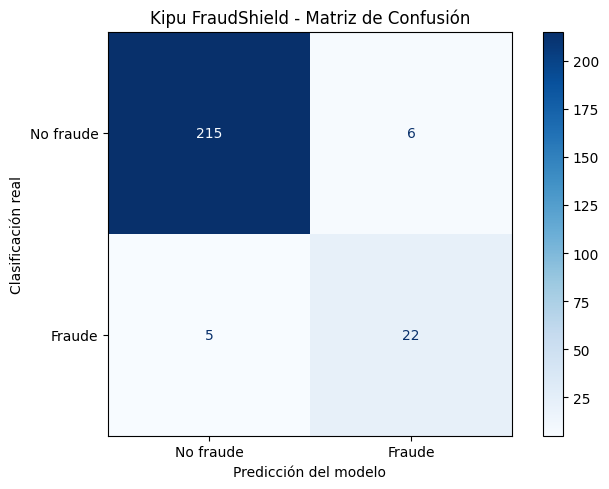

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No fraude", "Fraude"],
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("Kipu FraudShield - Matriz de Confusión")
plt.xlabel("Predicción del modelo")
plt.ylabel("Clasificación real")
plt.tight_layout()
plt.show()

### **8.9. Importancia de las variables**

=== 15 VARIABLES MÁS IMPORTANTES ===
                               Variable  Importancia
         numericas__intentos_previos_1h     0.324576
       categoricas__pais_transaccion_CL     0.108855
numericas__transacciones_previas_limpio     0.035113
                 categoricas__canal_pos     0.027647
                categoricas__moneda_CLP     0.027459
                 categoricas__canal_web     0.024111
                 numericas__ip_faltante     0.022288
          categoricas__tipo_desconocido     0.022108
categoricas__pais_declarado_desconocido     0.020761
                 categoricas__canal_api     0.020366
     numericas__dispositivo_id_faltante     0.019469
                categoricas__moneda_USD     0.019335
       categoricas__pais_transaccion_NG     0.018240
       categoricas__pais_transaccion_US     0.016641
            numericas__nivel_kyc_limpio     0.016151


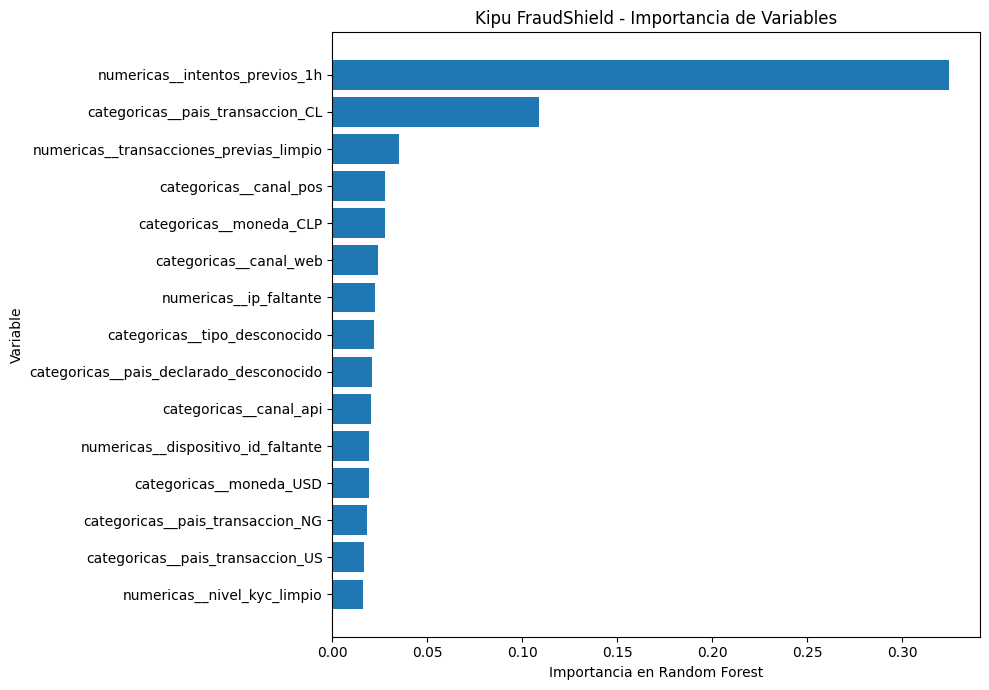

In [ ]:
# Obtener el preprocesador y el clasificador
prepro = modelo_fraude.named_steps["preprocesamiento"]
clasificador = modelo_fraude.named_steps["clasificador"]

# Obtener nombres de variables después del One-Hot Encoding
nombres_variables = prepro.get_feature_names_out()

# Obtener importancia de las variables
importancias = pd.DataFrame({
    "Variable": nombres_variables,
    "Importancia": clasificador.feature_importances_
})

# Ordenar de mayor a menor
importancias = importancias.sort_values(
    "Importancia",
    ascending=False
)

print("=== 15 VARIABLES MÁS IMPORTANTES ===")
print(importancias.head(15).to_string(index=False))

# Visualización
top_15 = importancias.head(15).sort_values("Importancia")

plt.figure(figsize=(10, 7))
plt.barh(top_15["Variable"], top_15["Importancia"])

plt.title("Kipu FraudShield - Importancia de Variables")
plt.xlabel("Importancia en Random Forest")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

### **8.10. Revisar qué aprendió el modelo**

In [ ]:
analisis = df_modelo[
    ["intentos_previos_1h", "es_fraude_limpio"]
].copy()

print("=== INTENTOS PREVIOS SEGÚN CLASE ===")

print(
    analisis.groupby("es_fraude_limpio")[
        "intentos_previos_1h"
    ].agg(["count", "mean", "median", "min", "max"])
)

print("\n=== DISTRIBUCIÓN POR INTENTOS ===")

print(
    pd.crosstab(
        analisis["intentos_previos_1h"].fillna(-1),
        analisis["es_fraude_limpio"]
    )
)

=== INTENTOS PREVIOS SEGÚN CLASE ===
                  count      mean  median  min   max
es_fraude_limpio                                    
0                  1051  0.731684     0.0  0.0   3.0
1                   135  5.333333     6.0  1.0  12.0

=== DISTRIBUCIÓN POR INTENTOS ===
es_fraude_limpio       0   1
intentos_previos_1h         
-1.0                  62   7
 0.0                 540   0
 1.0                 311  25
 2.0                 142   0
 3.0                  58  38
 4.0                   0   1
 6.0                   0  45
 7.0                   0   1
 12.0                  0  25


### **8.11. Comparación del modelo con y sin intentos previos**

In [ ]:
# Excluir intentos previos y su indicador de ausencia
columnas_excluir = [
    "intentos_previos_1h",
    "intentos_previos_desconocidos"
]

numericas_reducidas = [
    col for col in numericas_finales
    if col not in columnas_excluir
]

# Crear preprocesador reducido
preprocesador_reducido = ColumnTransformer(
    transformers=[
        (
            "numericas",
            clone(pipeline_numerico),
            numericas_reducidas
        ),
        (
            "categoricas",
            clone(pipeline_categorico),
            categoricas_finales
        )
    ]
)

# Crear segundo modelo Random Forest
modelo_sin_intentos = Pipeline(steps=[
    ("preprocesamiento", preprocesador_reducido),
    ("clasificador", RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Seleccionar variables restantes
columnas_reducidas = (
    numericas_reducidas + categoricas_finales
)

# Entrenar el segundo modelo
modelo_sin_intentos.fit(
    X_train_preparado[columnas_reducidas],
    y_train
)

# Obtener predicciones
pred_sin = modelo_sin_intentos.predict(
    X_test_preparado[columnas_reducidas]
)

prob_sin = modelo_sin_intentos.predict_proba(
    X_test_preparado[columnas_reducidas]
)[:, 1]

# Comparar métricas
comparacion = pd.DataFrame({
    "Métrica": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "Average Precision"
    ],
    "Modelo original": [
        accuracy,
        precision,
        recall,
        f1,
        pr_auc
    ],
    "Modelo sin intentos": [
        accuracy_score(y_test, pred_sin),
        precision_score(y_test, pred_sin, zero_division=0),
        recall_score(y_test, pred_sin, zero_division=0),
        f1_score(y_test, pred_sin, zero_division=0),
        average_precision_score(y_test, prob_sin)
    ]
})

print("=== COMPARACIÓN DE MODELOS ===")
print(comparacion.round(4).to_string(index=False))

print("\n=== MATRIZ DE CONFUSIÓN SIN INTENTOS ===")
print(confusion_matrix(y_test, pred_sin))

=== COMPARACIÓN DE MODELOS ===
          Métrica  Modelo original  Modelo sin intentos
         Accuracy           0.9556               0.8952
        Precision           0.7857               0.5172
           Recall           0.8148               0.5556
         F1-score           0.8000               0.5357
Average Precision           0.9056               0.5052

=== MATRIZ DE CONFUSIÓN SIN INTENTOS ===
[[207  14]
 [ 12  15]]


### **8.12. Comparación del modelo con y sin intentos previos**

In [ ]:
# Conservar el modelo con mejores resultados experimentales
modelo_seleccionado = modelo_fraude

# Guardar las columnas utilizadas durante el entrenamiento
variables_seleccionadas = X_train_preparado.columns.tolist()

# Variables que no deben utilizarse por fuga de información
variables_prohibidas = [
    "es_fraude",
    "es_fraude_limpio",
    "revisado_por_analista",
    "motivo_bloqueo",
    "resultado_autorizacion"
]

# Comprobar que no estén presentes
prohibidas_en_modelo = [
    col for col in variables_seleccionadas
    if col in variables_prohibidas
]

print("=== MODELO SELECCIONADO ===")

print("Algoritmo: Random Forest")
print("Variables utilizadas:", len(variables_seleccionadas))

print("\nVariables prohibidas encontradas:")
print(prohibidas_en_modelo)

print("\nResultados experimentales:")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")
print(f"Average Precision: {pr_auc:.4f}")

print("\nEstado: CANDIDATO EXPERIMENTAL")
print("Pendiente: validación de disponibilidad temporal")

=== MODELO SELECCIONADO ===
Algoritmo: Random Forest
Variables utilizadas: 26

Variables prohibidas encontradas:
[]

Resultados experimentales:
Accuracy: 0.9556
Precision: 0.7857
Recall: 0.8148
F1-score: 0.8000
Average Precision: 0.9056

Estado: CANDIDATO EXPERIMENTAL
Pendiente: validación de disponibilidad temporal


### **9.1. Validación temporal del modelo**

In [ ]:
df = df_modelo.copy()

print("=== VALIDACIÓN TEMPORAL ===")

print("Transacciones etiquetadas:", len(df))

# Obtener fecha calendario de la transacción
fecha_tx = df["timestamp_utc"].dt.tz_localize(None)

fecha_tx = fecha_tx.fillna(
    df["timestamp_sin_zona"]
)

# Comparar fechas de registro de usuarios
fecha_usuario = pd.to_datetime(
    df["fecha_registro"],
    errors="coerce"
)

# Margen de un día para evitar falsas alertas
# por diferencias de zona horaria
usuarios_posteriores = (
    fecha_usuario.dt.normalize()
    > fecha_tx.dt.normalize() + pd.Timedelta(days=1)
)

print("\nUsuarios registrados después de la transacción:")
print(usuarios_posteriores.sum())

# Comparar dispositivos solo cuando ambas fechas
# tienen zona horaria conocida
fechas_comparables = (
    df["timestamp_utc"].notna()
    & df["primera_vez_utc"].notna()
)

dispositivos_posteriores = (
    fechas_comparables
    & (
        df["primera_vez_utc"]
        > df["timestamp_utc"] + pd.Timedelta(days=1)
    )
)

print("\nTransacciones con fechas de dispositivo comparables:")
print(fechas_comparables.sum())

print("Dispositivos registrados después de la transacción:")
print(dispositivos_posteriores.sum())

print("\n=== VARIABLES SENSIBLES A REVISIÓN ===")

variables_revisar = [
    "intentos_previos_1h",
    "transacciones_previas_limpio",
    "nivel_kyc_limpio",
    "verificado",
    "emulador"
]

for variable in variables_revisar:
    print(
        f"{variable}:",
        "PRESENTE" if variable in variables_seleccionadas
        else "NO UTILIZADA"
    )

print("\nModelo seleccionado:", type(
    modelo_seleccionado.named_steps["clasificador"]
).__name__)

=== VALIDACIÓN TEMPORAL ===
Transacciones etiquetadas: 1255

Usuarios registrados después de la transacción:
229

Transacciones con fechas de dispositivo comparables:
207
Dispositivos registrados después de la transacción:
41

=== VARIABLES SENSIBLES A REVISIÓN ===
intentos_previos_1h: PRESENTE
transacciones_previas_limpio: PRESENTE
nivel_kyc_limpio: PRESENTE
verificado: PRESENTE
emulador: PRESENTE

Modelo seleccionado: RandomForestClassifier


#### **9.1.1. Investigar las inconsistencias temporales**

In [ ]:
df = df_modelo.copy()

# Fecha de transacción, conservando la referencia disponible
fecha_tx = (
    df["timestamp_utc"]
    .dt.tz_localize(None)
    .fillna(df["timestamp_sin_zona"])
)

# Usuarios con registro posterior por más de un día
usuarios_posteriores = (
    df["fecha_registro"].notna()
    & (
        df["fecha_registro"].dt.normalize()
        > fecha_tx.dt.normalize() + pd.Timedelta(days=1)
    )
)

# Dispositivos con primera aparición posterior
# Solo comparar fechas con zona horaria conocida
dispositivos_posteriores = (
    df["timestamp_utc"].notna()
    & df["primera_vez_utc"].notna()
    & (
        df["primera_vez_utc"]
        > df["timestamp_utc"] + pd.Timedelta(days=1)
    )
)

print("=== INCONSISTENCIAS TEMPORALES ===")

print("Usuarios posteriores:", usuarios_posteriores.sum())
print("Dispositivos posteriores:", dispositivos_posteriores.sum())

print(
    "Transacciones con alguna inconsistencia:",
    (usuarios_posteriores | dispositivos_posteriores).sum()
)

print("\n=== ETIQUETAS DE LOS CASOS ===")

print("Usuarios posteriores:")
print(
    df.loc[usuarios_posteriores, "es_fraude_limpio"]
    .value_counts(dropna=False)
)

print("\nDispositivos posteriores:")
print(
    df.loc[dispositivos_posteriores, "es_fraude_limpio"]
    .value_counts(dropna=False)
)

print("\n=== EJEMPLOS DE USUARIOS ===")

print(
    df.loc[
        usuarios_posteriores,
        ["transaccion_id", "usuario_id",
         "timestamp_original", "fecha_registro",
         "es_fraude_limpio"]
    ].head(5).to_string(index=False)
)

print("\n=== EJEMPLOS DE DISPOSITIVOS ===")

print(
    df.loc[
        dispositivos_posteriores,
        ["transaccion_id", "dispositivo_id",
         "timestamp_utc", "primera_vez_utc",
         "es_fraude_limpio"]
    ].head(5).to_string(index=False)
)

=== INCONSISTENCIAS TEMPORALES ===
Usuarios posteriores: 229
Dispositivos posteriores: 41
Transacciones con alguna inconsistencia: 258

=== ETIQUETAS DE LOS CASOS ===
Usuarios posteriores:
es_fraude_limpio
0    203
1     26
Name: count, dtype: Int64

Dispositivos posteriores:
es_fraude_limpio
0    40
1     1
Name: count, dtype: Int64

=== EJEMPLOS DE USUARIOS ===
transaccion_id usuario_id        timestamp_original fecha_registro  es_fraude_limpio
     TX7000632   KP304029      2024-05-08T20:47:47Z     2025-01-10                 0
     TX7001112   KP303459       2025-03-23 08:40:42     2026-04-09                 0
     TX7000859   KP301217       2024-08-26 12:09:15     2025-08-22                 0
     TX7000862   KP300862      2026-02-07T00:04:57Z     2026-06-17                 0
     TX7001130   KP304879 2025-01-20 20:42:42-04:00     2025-04-14                 0

=== EJEMPLOS DE DISPOSITIVOS ===
transaccion_id dispositivo_id             timestamp_utc           primera_vez_utc  es_frau

#### **9.1.2. Entrenar una versión conservadora**

In [ ]:
# Variables numéricas de la transacción
numericas_conservadoras = [
    "monto_negativo",
    "monto_cero",
    "moneda_desconocida",
    "monto_ambiguo",
    "coordenadas_sospechosas",
    "dispositivo_id_faltante",
    "comercio_id_faltante",
    "ip_faltante"
]

# Variables categóricas de la transacción
categoricas_conservadoras = [
    "moneda",
    "canal",
    "mcc",
    "pais_transaccion"
]

columnas_conservadoras = (
    numericas_conservadoras + categoricas_conservadoras
)

# Preprocesamiento independiente
preprocesador_conservador = ColumnTransformer(
    transformers=[
        ("numericas",
         clone(pipeline_numerico),
         numericas_conservadoras),

        ("categoricas",
         clone(pipeline_categorico),
         categoricas_conservadoras)
    ]
)

# Modelo conservador
modelo_conservador = Pipeline(steps=[
    ("preprocesamiento", preprocesador_conservador),
    ("clasificador", RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Entrenar con los mismos grupos de entrenamiento
modelo_conservador.fit(
    X_train_preparado[columnas_conservadoras],
    y_train
)

# Evaluar con el mismo conjunto de prueba
pred_conservador = modelo_conservador.predict(
    X_test_preparado[columnas_conservadoras]
)

prob_conservador = modelo_conservador.predict_proba(
    X_test_preparado[columnas_conservadoras]
)[:, 1]

print("=== MODELO CONSERVADOR ===")

print("Variables utilizadas:", len(columnas_conservadoras))

print("Accuracy:",
      round(accuracy_score(y_test, pred_conservador), 4))

print("Precision:",
      round(precision_score(
          y_test, pred_conservador, zero_division=0), 4))

print("Recall:",
      round(recall_score(
          y_test, pred_conservador, zero_division=0), 4))

print("F1-score:",
      round(f1_score(
          y_test, pred_conservador, zero_division=0), 4))

print("Average Precision:",
      round(average_precision_score(
          y_test, prob_conservador), 4))

print("\n=== MATRIZ DE CONFUSIÓN ===")
print(confusion_matrix(y_test, pred_conservador))

=== MODELO CONSERVADOR ===
Variables utilizadas: 12
Accuracy: 0.8831
Precision: 0.4773
Recall: 0.7778
F1-score: 0.5915
Average Precision: 0.548

=== MATRIZ DE CONFUSIÓN ===
[[198  23]
 [  6  21]]


#### **9.2. Entrenar una versión conservadora**

In [ ]:
# Carpeta de destino en Google Drive
ruta_modelos = "/content/drive/MyDrive/Kipu FraudShield/modelos"

os.makedirs(ruta_modelos, exist_ok=True)

# Seleccionar modelo conservador
modelo_para_exportar = modelo_conservador

# Ruta del archivo
ruta_modelo = os.path.join(
    ruta_modelos,
    "kipu_fraudshield_conservador.joblib"
)

# Guardar pipeline completo
joblib.dump(modelo_para_exportar, ruta_modelo)

# Guardar información de las variables necesarias
metadata = {
    "nombre": "Kipu FraudShield",
    "version": "ep2_prototipo",
    "algoritmo": "RandomForestClassifier",
    "variables": columnas_conservadoras,
    "numericas": numericas_conservadoras,
    "categoricas": categoricas_conservadoras,
    "estado": "experimental",
    "limitaciones": (
        "Modelo entrenado con una muestra etiquetada reducida. "
        "Pendiente validacion temporal completa e independiente."
    )
}

ruta_metadata = os.path.join(
    ruta_modelos,
    "kipu_fraudshield_metadata.json"
)

with open(ruta_metadata, "w", encoding="utf-8") as archivo:
    json.dump(metadata, archivo, indent=4, ensure_ascii=False)

print("=== EXPORTACIÓN COMPLETADA ===")

print("Modelo guardado en:")
print(ruta_modelo)

print("\nMetadata guardada en:")
print(ruta_metadata)

print("\nArchivos existentes:")
print(os.listdir(ruta_modelos))

print("\nTamaño del modelo (MB):")
print(round(os.path.getsize(ruta_modelo) / (1024**2), 2))

=== EXPORTACIÓN COMPLETADA ===
Modelo guardado en:
/content/drive/MyDrive/Kipu FraudShield/modelos/kipu_fraudshield_conservador.joblib

Metadata guardada en:
/content/drive/MyDrive/Kipu FraudShield/modelos/kipu_fraudshield_metadata.json

Archivos existentes:
['kipu_fraudshield_conservador.joblib', 'kipu_fraudshield_metadata.json']

Tamaño del modelo (MB):
1.51


#### **9.3. Verificar el modelo exportado**

In [ ]:
# Cargar modelo desde Google Drive
modelo_cargado = joblib.load(ruta_modelo)

# Cargar metadata
with open(ruta_metadata, "r", encoding="utf-8") as archivo:
    metadata_cargada = json.load(archivo)

print("=== VERIFICACIÓN DEL MODELO ===")

print("Modelo cargado correctamente.")
print("Nombre:", metadata_cargada["nombre"])
print("Versión:", metadata_cargada["version"])
print("Estado:", metadata_cargada["estado"])

print("\nVariables requeridas:")
print(len(metadata_cargada["variables"]))

# Seleccionar ejemplos del conjunto de prueba
ejemplos = X_test_preparado[
    metadata_cargada["variables"]
].head(5).copy()

# Obtener predicciones
predicciones = modelo_cargado.predict(ejemplos)

# Obtener probabilidades estimadas de fraude
probabilidades = modelo_cargado.predict_proba(ejemplos)[:, 1]

# Comprobar que la versión cargada y la original coinciden
probabilidades_originales = modelo_para_exportar.predict_proba(
    ejemplos
)[:, 1]

np.testing.assert_allclose(
    probabilidades,
    probabilidades_originales
)

print("\n=== PREDICCIONES DE PRUEBA ===")

resultados = pd.DataFrame({
    "Prediccion": predicciones,
    "Probabilidad_fraude": probabilidades.round(4)
})

print(resultados.to_string(index=False))

print("\nVerificación: predicciones idénticas al modelo original.")
print("Modelo listo para integrarse en el prototipo.")

=== VERIFICACIÓN DEL MODELO ===
Modelo cargado correctamente.
Nombre: Kipu FraudShield
Versión: ep2_prototipo
Estado: experimental

Variables requeridas:
12

=== PREDICCIONES DE PRUEBA ===
 Prediccion  Probabilidad_fraude
          0               0.1883
          0               0.3942
          0               0.2195
          0               0.0146
          1               0.6087

Verificación: predicciones idénticas al modelo original.
Modelo listo para integrarse en el prototipo.
